# Spring–Mass Dynamics and the Graph Fourier Transform

A structural engineer who has done modal analysis has already computed a graph Fourier transform —
without calling it that. This lesson makes the correspondence exact, states the conditions under
which it holds, and shows where it breaks.

The claim, stated precisely up front so we can test it rather than admire it:

> For a network of **equal masses** connected by linear springs, with no other degrees of freedom,
> the stiffness matrix is $\mathbf{k}=k_0L$ for the graph Laplacian $L$; the **mode shapes are the
> Laplacian eigenvectors**; the **normal coordinates are the graph Fourier coefficients**; and the
> natural frequencies are $\omega_r=\sqrt{k_0\lambda_r/m_0}$.
>
> Change the masses and the first three statements survive only with a modified inner product. The
> Laplacian by itself specifies neither the masses nor the time dynamics.

**Audience.** Introductory structural mechanics and linear algebra; new to graph signal processing.

**Scope.** One three-mass system throughout. Undirected, non-negative spring stiffnesses, one scalar
displacement per node. Undamped until Section 6, where light *modal* damping is added after
resonance has been explained. General frames — beams, joints, rotations — need geometry and multiple
degrees of freedom per node and are out of scope.

### Notation

| Structural mechanics | Graph analysis correspondence |
|---|---|
| Displacements $\mathbf{q}(t)$ [m] | node signal $x(t)$ |
| Mass, stiffness, damping $\mathbf{m},\mathbf{k},\mathbf{c}$ | $\mathbf{k}=k_0L$; an ordinary GFT needs no dynamic model at all |
| Mode shapes $\phi_r$, matrix $\Phi$ | Laplacian eigenvectors $u_r$, matrix $U$ — **for equal masses** |
| Normal (modal) coordinates $\xi_r(t)$ | GFT coefficients $\hat{x}_r(t)$, with matching normalisation |
| Generalised mass $M_r=\phi_r^\top\mathbf{m}\phi_r$ | equals $m_0$ for equal masses and Euclidean-unit modes |
| Applied load $\mathbf{F}$ [N]; generalised force $\Xi_r=\phi_r^\top\mathbf{F}$ | node force signal; its GFT coefficient when $\Phi=U$ |
| Natural frequency $\omega_r$ [rad/s]; forcing frequency $\Omega$ [rad/s] | $\omega_r^2=(k_0/m_0)\lambda_r$; $\lambda_r$ is **graph** frequency |

> 📖 **References.** The structural dynamics follows
> [Lagace, *MIT 16.20 Handout 6, (Introduction to) Structural Dynamics*,
> 2002](https://ocw.mit.edu/courses/16-20-structural-mechanics-fall-2002/35b10a9694157002e14893014de39058_ho6.pdf):
> pp. 1–3 for free vibration, the Dirac delta and unit impulse response, Duhamel's integral and
> harmonic forcing; pp. 4–5 for the multi-degree-of-freedom eigenproblem
> $|\mathbf{k}-\omega^2\mathbf{m}|=0$, modal orthogonality $\phi^{(r)\top}\mathbf{m}\phi^{(s)}=\delta_{rs}M_r$,
> and the normal equations. The handout uses under-tilde vectors and $\phi^{(r)}$ superscripts; we
> write vectors in boldface and modes as $\phi_r$, but every equation below is the handout's.
> The graph side follows
> [Shuman et al., *The Emerging Field of Signal Processing on Graphs*
> (2013)](https://arxiv.org/abs/1211.0053), Sections II–III, for the Laplacian, its eigenvectors as a
> Fourier basis, graph variation and filtering.

### Roadmap

1. Assemble the springs and recover the Laplacian
2. Compute and interpret the modes
3. The GFT **is** modal decomposition
4. Free oscillation from initial conditions
5. A Dirac impulse: kick, then free motion
6. Sustained forcing, Duhamel's integral, resonance — then light damping
7. Correspondence, scope, and verification


In [1]:
# ============================== CONFIGURATION ==============================
# Every physical quantity used anywhere in this notebook is set here.
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import TwoSlopeNorm
from scipy.integrate import solve_ivp, cumulative_trapezoid
from IPython.display import HTML, display

# --- physical parameters ---------------------------------------------------
M0     = 1.0        # mass of each node                        [kg]
K0     = 4.0        # reference spring stiffness               [N/m]
N      = 3          # number of masses (degrees of freedom)    [-]

# --- initial conditions ----------------------------------------------------
Q0_LOCAL = np.array([1.0, 0.0, 0.0])   # localised release, displacement    [m]
V0_ZERO  = np.zeros(N)                 # released from rest                 [m/s]

# --- impulse (Section 5) ---------------------------------------------------
J_VEC  = np.array([0.0, 0.0, 1.0])     # impulse applied to node 3          [N*s]
T_KICK = 0.5                           # time of the kick                   [s]

# --- harmonic forcing (Section 6) ------------------------------------------
F0     = 1.0                           # forcing amplitude                  [N]
B_ROOF = np.array([0.0, 0.0, 1.0])     # spatial load pattern: roof level   [-]
ZETA   = 0.05                          # modal damping ratio, Section 6 ext [-]

# --- simulation / display --------------------------------------------------
T_END  = 12.0       # simulation duration                      [s]
NT     = 2401       # time samples (solver output grid)        [-]
FPS    = 20         # animation playback rate                  [frames/s]
NFRAME = 40         # animation frames per clip                [-]
ANIM_FIGSIZE = (10.2, 4.2)   # inches; with savefig.dpi below this sets the
ANIM_DPI     = 56            # embedded frame size. Each clip is a self-contained
                             # HTML+JS movie whose size scales as dpi^2 * area *
                             # frames, so these three numbers are the size budget.
T_ANIM = 6.0        # animations cover [0, T_ANIM] s, the static plots the full
                    # T_END. Windowing keeps enough frames per cycle to resolve the
                    # fastest mode: NFRAME/T_ANIM must comfortably exceed 2/T_min.
MAG    = 1.0        # DISPLACEMENT MAGNIFICATION in animations [-]
                    #   drawn offset = MAG * q_i, in the same metres as the
                    #   spacing below. MAG = 1 means true scale.
SPACING = 1.5       # undeformed spacing between masses        [m]
SEED   = 7
rng = np.random.default_rng(SEED)

t_grid = np.linspace(0.0, T_END, NT)

# --- plotting conventions, carried over from the other lessons -------------
plt.rcParams.update({
    "figure.dpi": 110, "figure.constrained_layout.use": True,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
    "savefig.dpi": ANIM_DPI,        # keeps embedded animations small
    "animation.embed_limit": 60.0,  # MB
})
C_LINE, C_RED, C_GREEN, C_ORANGE = "#2b6cb0", "#c53030", "#2f855a", "#e07a3f"
MODE_COLORS = [C_LINE, C_ORANGE, C_GREEN]

import scipy, matplotlib
for nm, mod in [("numpy", np), ("scipy", scipy), ("networkx", nx), ("matplotlib", matplotlib)]:
    print(f"{nm:<12} {mod.__version__}")
print(f"\nm0 = {M0} kg,  k0 = {K0} N/m,  sqrt(k0/m0) = {np.sqrt(K0/M0):.4f} rad/s")
print(f"animation displacement magnification MAG = {MAG} (1.0 = true scale)")

numpy        2.5.3
scipy        1.18.1
networkx     3.6.1
matplotlib   3.11.1

m0 = 1.0 kg,  k0 = 4.0 N/m,  sqrt(k0/m0) = 2.0000 rad/s
animation displacement magnification MAG = 1.0 (1.0 = true scale)


---
## 1. Assemble the springs and recover the Laplacian

### One spring

A linear spring of stiffness $k_{ij}$ [N/m] between nodes $i$ and $j$ cares only about its
**extension**, $q_i-q_j$ [m]. Its stored elastic energy is

$$V_{ij} \;=\; \tfrac12\,k_{ij}\,(q_i-q_j)^2 .$$

Differentiating with respect to the two displacements gives the restoring forces, and collecting
them produces the $2\times2$ **element stiffness matrix**

$$\mathbf{k}^{(ij)} \;=\; k_{ij}\begin{bmatrix}1&-1\\-1&1\end{bmatrix},$$

which is already a two-node graph Laplacian scaled by $k_{ij}$. Everything that follows is
bookkeeping on top of this one observation.

### Assembly

Place $N=3$ equal masses $m_0$ in a row, connect 1–2 and 2–3 with springs of stiffness $k_0$, and
leave both ends free. Assembling means adding each element matrix into the global one at the rows
and columns of its two nodes. Writing $w_{ij}$ for the connection weight ($k_{ij}=k_0w_{ij}$),
$D_{ii}=\sum_j w_{ij}$ and $L=D-W$:

$$\mathbf{k} \;=\; k_0 L, \qquad L=\begin{bmatrix}1&-1&0\\-1&2&-1\\0&-1&1\end{bmatrix}.$$

> ⚠️ **The diagonal is not a spring to ground.** $L_{ii}=2$ at the middle mass because *two* springs
> pull on it, not because it is attached to anything fixed. Handout 6 p. 4 gives the reading that
> settles this: $k_{ij}$ is "force at $i$ due to unit displacement at $j$ with other displacements
> equal to 0". Push node 2 by one metre while holding 1 and 3 — both springs resist, so the force is
> $2k_0$. Section 1.3 adds a genuine ground spring and the diagonal changes for a different reason.

Also keep two force signs apart: the **applied static** load satisfying $\mathbf{F}=\mathbf{k}\mathbf{q}$,
and the **restoring** force the springs exert on the masses, $-\mathbf{k}\mathbf{q}$, which is what
appears in Newton's second law.


In [2]:
# --- element stiffness, then assembly, done explicitly ----------------------
def element_stiffness(kij):
    """2x2 element matrix for one spring: k_ij * [[1,-1],[-1,1]]."""
    return kij * np.array([[1.0, -1.0], [-1.0, 1.0]])

EDGES = [(0, 1, 1.0), (1, 2, 1.0)]     # (node i, node j, weight w_ij)

k_assembled = np.zeros((N, N))
for i, j, w in EDGES:
    ke = element_stiffness(K0 * w)
    for a, ia in enumerate((i, j)):     # scatter the 2x2 block into the global matrix
        for b, jb in enumerate((i, j)):
            k_assembled[ia, jb] += ke[a, b]

# --- the same thing as a graph Laplacian -----------------------------------
Wadj = np.zeros((N, N))
for i, j, w in EDGES:
    Wadj[i, j] = Wadj[j, i] = w
Dmat = np.diag(Wadj.sum(axis=1))
Lfree = Dmat - Wadj

print("assembled stiffness k [N/m]:\n", k_assembled)
print("\nLaplacian L [-]:\n", Lfree.astype(int))
print(f"\nk == k0 * L exactly: {np.array_equal(k_assembled, K0 * Lfree)}")
print(f"L is symmetric: {np.array_equal(Lfree, Lfree.T)};  "
      f"row sums zero: {np.abs(Lfree @ np.ones(N)).max():.1e}")
print(f"\nmass matrix m = m0 * I  [kg]:\n{M0*np.eye(N)}")

# the quadratic form: strain energy as a sum over springs
q_demo = np.array([0.3, -0.1, 0.4])
V_edges = sum(0.5 * K0 * w * (q_demo[i] - q_demo[j]) ** 2 for i, j, w in EDGES)
V_matrix = 0.5 * q_demo @ (K0 * Lfree) @ q_demo
print(f"\nstrain energy of q = {q_demo} m")
print(f"  sum over springs  1/2 k_ij (q_i - q_j)^2 = {V_edges:.8f} J")
print(f"  quadratic form    1/2 q' (k0 L) q        = {V_matrix:.8f} J")

assembled stiffness k [N/m]:
 [[ 4. -4.  0.]
 [-4.  8. -4.]
 [ 0. -4.  4.]]

Laplacian L [-]:
 [[ 1 -1  0]
 [-1  2 -1]
 [ 0 -1  1]]

k == k0 * L exactly: True
L is symmetric: True;  row sums zero: 0.0e+00

mass matrix m = m0 * I  [kg]:
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

strain energy of q = [ 0.3 -0.1  0.4] m
  sum over springs  1/2 k_ij (q_i - q_j)^2 = 0.82000000 J
  quadratic form    1/2 q' (k0 L) q        = 0.82000000 J


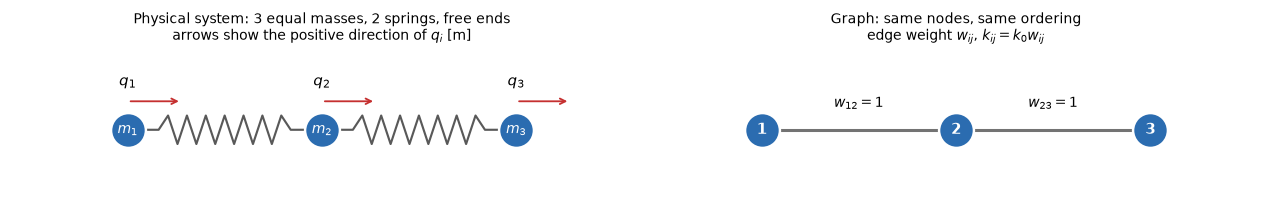

In [3]:
# --- the spring system and its graph, drawn side by side, SAME node order ---
def spring_path(x1, x2, y=0.0, coils=7, amp=0.11):
    """Zigzag polyline for a spring drawn between x1 and x2."""
    lead = 0.16 * (x2 - x1)
    xs = [x1, x1 + lead]
    ys = [y, y]
    n = 2 * coils
    for s in range(1, n):
        xs.append(x1 + lead + (x2 - x1 - 2 * lead) * s / n)
        ys.append(y + amp * (1 if s % 2 else -1))
    xs += [x2 - lead, x2]
    ys += [y, y]
    return np.array(xs), np.array(ys)

X_REST = SPACING * np.arange(N)           # undeformed mass positions [m]
GPOS = {i: (float(X_REST[i]), 0.0) for i in range(N)}   # FIXED graph node positions

Gnx = nx.Graph()
Gnx.add_nodes_from(range(N))
Gnx.add_weighted_edges_from([(i, j, w) for i, j, w in EDGES])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 2.9))
ax = axes[0]
for i, j, w in EDGES:
    sx, sy = spring_path(X_REST[i], X_REST[j])
    ax.plot(sx, sy, color="0.35", lw=1.4)
ax.scatter(X_REST, np.zeros(N), s=520, c=C_LINE, edgecolor="white", linewidth=1.6, zorder=3)
for i in range(N):
    ax.text(X_REST[i], 0, f"$m_{i+1}$", ha="center", va="center",
            color="white", fontsize=9, fontweight="bold", zorder=4)
    ax.annotate(f"$q_{i+1}$", (X_REST[i], 0.34), ha="center", fontsize=10)
    ax.annotate("", xy=(X_REST[i] + 0.42, 0.22), xytext=(X_REST[i], 0.22),
                arrowprops=dict(arrowstyle="->", color=C_RED, lw=1.2))
ax.set_xlim(-0.9, X_REST[-1] + 0.9); ax.set_ylim(-0.55, 0.62)
ax.set_aspect("equal"); ax.set_axis_off(); ax.grid(False)
ax.set_title("Physical system: 3 equal masses, 2 springs, free ends\n"
             "arrows show the positive direction of $q_i$ [m]", fontsize=9)

ax = axes[1]
nx.draw_networkx_edges(Gnx, GPOS, ax=ax, width=2.0, edge_color="0.45")
nx.draw_networkx_nodes(Gnx, GPOS, ax=ax, node_size=520, node_color=C_LINE,
                       edgecolors="white", linewidths=1.6)
nx.draw_networkx_labels(Gnx, GPOS, ax=ax, labels={i: f"{i+1}" for i in range(N)},
                        font_color="white", font_weight="bold", font_size=10)
for i, j, w in EDGES:
    ax.annotate(f"$w_{{{i+1}{j+1}}}={w:g}$",
                ((X_REST[i] + X_REST[j]) / 2, 0.17), ha="center", fontsize=9)
ax.set_xlim(-0.9, X_REST[-1] + 0.9); ax.set_ylim(-0.55, 0.62)
ax.set_aspect("equal"); ax.set_axis_off(); ax.grid(False)
ax.set_title("Graph: same nodes, same ordering\nedge weight $w_{ij}$, $k_{ij}=k_0w_{ij}$",
             fontsize=9)
plt.show()

### A spring to ground: the grounded Laplacian

Now anchor node 1 to a fixed wall with another spring of stiffness $k_0$. That spring's element
matrix involves the wall's degree of freedom, which is **prescribed to be zero**. Eliminating a
prescribed degree of freedom means deleting its row and column *after* assembly — and the surviving
$(1,1)$ entry keeps the ground spring's contribution. The result is

$$L_g \;=\; L + e_1e_1^\top \;=\; \begin{bmatrix}2&-1&0\\-1&2&-1\\0&-1&1\end{bmatrix},
\qquad \mathbf{k}_g=k_0L_g .$$

This is the classic **three-storey shear building**: node 1 is the first floor tied to the
foundation, node 3 is the roof, and each $k_0$ is a storey stiffness.

> ⚠️ **$L_g$ is a *grounded* Laplacian, not the Laplacian of a three-node graph.** Its rows do not
> sum to zero, so $L_g\mathbf{1}\ne0$: there is no rigid-body mode, because rigid translation now
> stretches the ground spring. Everything in Sections 2–6 applies to it, but the "constant vector is
> in the null space" facts of ordinary graph Laplacians do not. Equivalently, it *is* the ordinary
> Laplacian of a **four**-node graph (three masses plus the wall) with the wall's row and column
> removed.


In [4]:
e1 = np.zeros(N); e1[0] = 1.0
Lgnd = Lfree + np.outer(e1, e1)

print("grounded Laplacian L_g [-]:\n", Lgnd.astype(int))
print(f"\nL   @ 1 = {Lfree @ np.ones(N)}   <- ordinary Laplacian: rigid translation is free")
print(f"L_g @ 1 = {Lgnd @ np.ones(N)}   <- grounded: translating the whole frame stretches")
print("                                    the ground spring, so it costs energy")

# Derive L_g the long way: build the 4-node graph (wall = node 0) and delete its row/column.
W4 = np.zeros((4, 4))
W4[0, 1] = W4[1, 0] = 1.0                       # wall  <-> mass 1
W4[1, 2] = W4[2, 1] = 1.0                       # mass 1 <-> mass 2
W4[2, 3] = W4[3, 2] = 1.0                       # mass 2 <-> mass 3
L4 = np.diag(W4.sum(1)) - W4
print(f"\n4-node Laplacian (wall is index 0):\n{L4.astype(int)}")
print(f"delete the wall's row and column -> equals L_g: "
      f"{np.array_equal(L4[1:, 1:], Lgnd)}")

grounded Laplacian L_g [-]:
 [[ 2 -1  0]
 [-1  2 -1]
 [ 0 -1  1]]

L   @ 1 = [0. 0. 0.]   <- ordinary Laplacian: rigid translation is free
L_g @ 1 = [1. 0. 0.]   <- grounded: translating the whole frame stretches
                                    the ground spring, so it costs energy

4-node Laplacian (wall is index 0):
[[ 1 -1  0  0]
 [-1  2 -1  0]
 [ 0 -1  2 -1]
 [ 0  0 -1  1]]
delete the wall's row and column -> equals L_g: True


---
## 2. Compute and interpret the modes

Newton's second law on each mass — inertia equals the **restoring** force — gives the undamped free
equation of motion (Handout 6 p. 4):

$$\mathbf{m}\ddot{\mathbf{q}} + \mathbf{k}\mathbf{q} \;=\; \mathbf{0}.$$

Substituting the trial solution $\mathbf{q}=\phi_r e^{i\omega_r t}$ turns this into the generalised
eigenproblem

$$\mathbf{k}\phi_r \;=\; \omega_r^2\,\mathbf{m}\,\phi_r, \qquad\text{equivalently}\qquad |\mathbf{k}-\omega^2\mathbf{m}|=0 .$$

**For equal masses**, $\mathbf{m}=m_0I$ and $\mathbf{k}=k_0L$, so this collapses to the *ordinary*
symmetric eigenproblem of the Laplacian:

$$k_0L\phi_r = \omega_r^2 m_0\phi_r \quad\Longleftrightarrow\quad L u_r=\lambda_r u_r,\qquad \boxed{\;\omega_r=\sqrt{\frac{k_0\lambda_r}{m_0}}\;}$$

with $\phi_r=u_r$ and $U^\top U=I$. This single line is the whole correspondence: **the mode shapes
of an equal-mass spring network are the Laplacian eigenvectors, and the squared natural frequencies
are the graph frequencies scaled by $k_0/m_0$.**


In [5]:
def modal_analysis(Lmat):
    """Eigenpairs of L with a fixed sign convention, plus natural frequencies."""
    lam, U = np.linalg.eigh(Lmat)
    order = np.argsort(lam)
    lam, U = lam[order], U[:, order]
    for r in range(U.shape[1]):
        # Sign convention: make the largest-magnitude entry positive. The sign of an
        # eigenvector is arbitrary (if L u = lam u then L(-u) = lam(-u)); we fix one so
        # plots are reproducible, NOT because the sign means anything.
        if U[np.argmax(np.abs(U[:, r])), r] < 0:
            U[:, r] *= -1.0
    omega = np.sqrt(np.maximum(K0 * lam / M0, 0.0))
    return lam, U, omega

lam_f, U_f, om_f = modal_analysis(Lfree)
lam_g, U_g, om_g = modal_analysis(Lgnd)

print("FREE CHAIN")
print(f"  graph frequencies lambda_r : {np.round(lam_f, 12)}   (exactly 0, 1, 3)")
print(f"  natural freqs omega_r      : {np.round(om_f, 6)} rad/s")
print(f"  periods 2*pi/omega_r       : {[f'{2*np.pi/w:.3f} s' if w > 1e-12 else 'inf' for w in om_f]}")
print("  mode shapes (columns, unit Euclidean norm):")
for r in range(N):
    scaled = U_f[:, r] / np.abs(U_f[:, r]).max()
    print(f"    u_{r+1} = {np.round(U_f[:, r], 6)}   proportional to {np.round(scaled, 4)}")
print("\n  textbook shapes (1,1,1), (1,0,-1), (1,-2,1) -- overlap with each u_r:")
for tgt in ([1, 1, 1], [1, 0, -1], [1, -2, 1]):
    v = np.array(tgt, float); v /= np.linalg.norm(v)
    print(f"    {str(tgt):12s} -> {np.round([abs(v @ U_f[:, r]) for r in range(N)], 10)}")

print("\nGROUNDED (three-storey shear building)")
print(f"  lambda_r : {np.round(lam_g, 6)}")
print(f"  closed form 4 sin^2((2r-1)pi/14) : "
      f"{np.round([4*np.sin((2*r-1)*np.pi/14)**2 for r in (1,2,3)], 6)}")
print(f"  omega_r  : {np.round(om_g, 6)} rad/s     periods: "
      f"{np.round(2*np.pi/om_g, 4)} s")
for r in range(N):
    print(f"    mode {r+1} shape / max : {np.round(U_g[:, r]/np.abs(U_g[:, r]).max(), 4)}")

FREE CHAIN
  graph frequencies lambda_r : [0. 1. 3.]   (exactly 0, 1, 3)
  natural freqs omega_r      : [0.       2.       3.464102] rad/s
  periods 2*pi/omega_r       : ['314212965.108 s', '3.142 s', '1.814 s']
  mode shapes (columns, unit Euclidean norm):
    u_1 = [0.57735 0.57735 0.57735]   proportional to [1. 1. 1.]
    u_2 = [ 0.707107 -0.       -0.707107]   proportional to [ 1. -0. -1.]
    u_3 = [-0.408248  0.816497 -0.408248]   proportional to [-0.5  1.  -0.5]

  textbook shapes (1,1,1), (1,0,-1), (1,-2,1) -- overlap with each u_r:
    [1, 1, 1]    -> [1. 0. 0.]
    [1, 0, -1]   -> [0. 1. 0.]
    [1, -2, 1]   -> [0. 0. 1.]

GROUNDED (three-storey shear building)
  lambda_r : [0.198062 1.554958 3.24698 ]
  closed form 4 sin^2((2r-1)pi/14) : [0.198062 1.554958 3.24698 ]
  omega_r  : [0.890084 2.493959 3.603875] rad/s     periods: [7.0591 2.5194 1.7435] s
    mode 1 shape / max : [0.445  0.8019 1.    ]
    mode 2 shape / max : [ 1.      0.445  -0.8019]
    mode 3 shape / max : [-

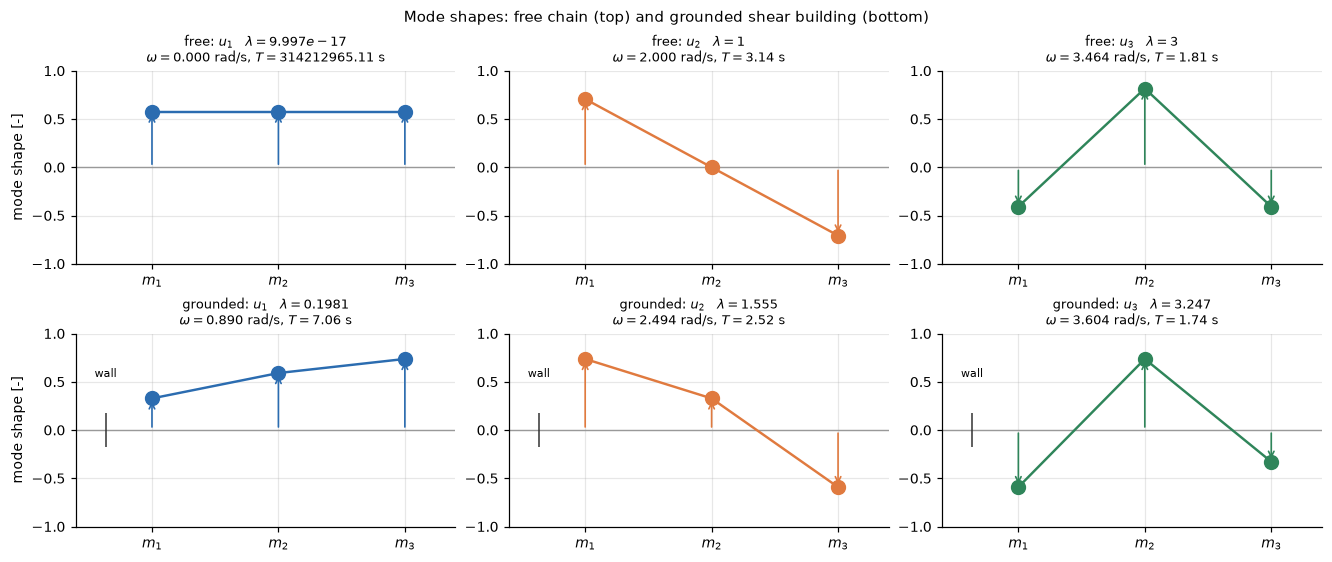

In [6]:
fig, axes = plt.subplots(2, N, figsize=(12, 5.0))
for row, (tag, lam_, U_, om_) in enumerate([("free", lam_f, U_f, om_f),
                                            ("grounded", lam_g, U_g, om_g)]):
    for r in range(N):
        ax = axes[row, r]
        ax.axhline(0, color="0.6", lw=0.9)
        ax.plot(X_REST, U_[:, r], "o-", ms=9, lw=1.6, color=MODE_COLORS[r])
        for i in range(N):
            ax.annotate("", xy=(X_REST[i], U_[i, r]), xytext=(X_REST[i], 0),
                        arrowprops=dict(arrowstyle="->", color=MODE_COLORS[r], lw=1.1))
        if tag == "grounded":
            ax.plot([-0.55], [0], marker="|", ms=22, color="0.2")
            ax.annotate("wall", (-0.55, 0.55), fontsize=7, ha="center")
        ax.set_ylim(-1.0, 1.0); ax.set_xlim(-0.9, X_REST[-1] + 0.6)
        ax.set_xticks(X_REST); ax.set_xticklabels([f"$m_{i+1}$" for i in range(N)])
        per = "$\\infty$" if om_[r] < 1e-12 else f"{2*np.pi/om_[r]:.2f} s"
        ax.set_title(f"{tag}: $u_{{{r+1}}}$   $\\lambda={lam_[r]:.4g}$\n"
                     f"$\\omega={om_[r]:.3f}$ rad/s, $T=${per}", fontsize=8.5)
        if r == 0:
            ax.set_ylabel("mode shape [-]")
fig.suptitle("Mode shapes: free chain (top) and grounded shear building (bottom)", fontsize=10)
plt.show()

Read the free-chain row left to right:

- **$u_1$, $\lambda_1=0$, $\omega_1=0$.** Every mass moves together: $(1,1,1)$. No spring stretches,
  so there is no restoring force and no oscillation. This is **rigid-body translation**, and it
  exists because the chain is unsupported. Its period is infinite — Section 4 shows it produces
  linear drift, not vibration.
- **$u_2$, $\lambda_2=1$.** The ends move oppositely and the centre stays still: $(1,0,-1)$. One sign
  change.
- **$u_3$, $\lambda_3=3$.** The centre opposes both ends: $(1,-2,1)$. Two sign changes, the largest
  extension per unit amplitude, the highest frequency.

The grounded row has **no zero mode** — the ground spring removes the rigid-body freedom — and its
first shape $(0.445,0.802,1)$ increases with height, which is exactly the first sway mode a
structural engineer expects from a shear building.

> ⚠️ **Two cautions that matter later.**
>
> **Sign is arbitrary.** If $Lu=\lambda u$ then $L(-u)=\lambda(-u)$. Our `modal_analysis` fixes a
> convention so the figures are reproducible; nothing physical distinguishes $u_r$ from $-u_r$, and
> no result below depends on the choice.
>
> **Variation increases with $\lambda_r$, but do not promise a zero-crossing count.** On a path
> graph, mode $r$ happens to have exactly $r-1$ sign changes. That is a property of paths, not of
> graphs. The statement that always holds is the Dirichlet one:
> $\lambda_r=u_r^\top Lu_r=\sum_{\{i,j\}\in E}w_{ij}(u_{r,i}-u_{r,j})^2$ — a higher graph frequency
> means more disagreement across springs, hence more stored energy per unit amplitude, hence a
> higher $\omega_r$.


In [7]:
# Dirichlet energy: the bridge between "graph frequency" and "stiffness"
print(f"{'mode':>6}{'lambda_r':>12}{'u_r^T L u_r':>14}{'sum over springs':>19}"
      f"{'sign changes':>14}")
for r in range(N):
    u = U_f[:, r]
    edge_sum = sum(w * (u[i] - u[j]) ** 2 for i, j, w in EDGES)
    sc = sum(1 for i, j, _ in EDGES if u[i] * u[j] < -1e-12)
    print(f"{r+1:>6}{lam_f[r]:12.6f}{u @ Lfree @ u:14.6f}{edge_sum:19.6f}{sc:14d}")
print("\nStrain energy stored by a unit-amplitude mode: V_r = 1/2 * k0 * lambda_r  [J]")
for r in range(N):
    print(f"  mode {r+1}: V = {0.5*K0*lam_f[r]:.4f} J   "
          f"(mode 1 stores nothing: translation stretches no spring)")

  mode    lambda_r   u_r^T L u_r   sum over springs  sign changes
     1    0.000000      0.000000           0.000000             0
     2    1.000000      1.000000           1.000000             0
     3    3.000000      3.000000           3.000000             2

Strain energy stored by a unit-amplitude mode: V_r = 1/2 * k0 * lambda_r  [J]
  mode 1: V = 0.0000 J   (mode 1 stores nothing: translation stretches no spring)
  mode 2: V = 2.0000 J   (mode 1 stores nothing: translation stretches no spring)
  mode 3: V = 6.0000 J   (mode 1 stores nothing: translation stretches no spring)


### Sidebar: unequal masses

Everything above used $\mathbf{m}=m_0I$. With unequal masses the eigenproblem
$\mathbf{k}\phi_r=\omega_r^2\mathbf{m}\phi_r$ is still fine, but the modes are orthogonal **in the
mass inner product**, not the Euclidean one (Handout 6 p. 5):

$$\phi_r^\top\mathbf{m}\,\phi_s=\delta_{rs}M_r, \qquad
\xi_r=\frac{\phi_r^\top\mathbf{m}\,\mathbf{q}}{M_r}.$$

So the modal coordinates use $\mathbf{m}$ as a weight, and $\Phi$ is no longer an orthogonal matrix.

> ⚠️ **This is where the correspondence stops being an identity.** A generalised eigensolver
> typically returns **mass-normalised** modes ($M_r=1$), so its coefficients are
> $\phi_r^\top\mathbf{m}\mathbf{q}$ — *not* $U^\top\mathbf{q}$. Those numbers are not the ordinary
> GFT of the raw displacement and must not be labelled as such. The demonstration below shows how
> far apart they get.


In [8]:
from scipy.linalg import eigh as geigh

m_uneq = np.diag([1.0, 3.0, 1.0])            # middle mass tripled  [kg]
lam_u, Phi_u = geigh(K0 * Lfree, m_uneq)     # generalised: k phi = w^2 m phi
om_u = np.sqrt(np.maximum(lam_u, 0.0))
Mr_u = np.array([Phi_u[:, r] @ m_uneq @ Phi_u[:, r] for r in range(N)])

print("unequal masses m = diag(1, 3, 1) kg")
print(f"  omega_r        : {np.round(om_u, 6)} rad/s   (equal-mass: {np.round(om_f, 6)})")
print(f"  generalised mass M_r : {np.round(Mr_u, 6)}  <- solver returned mass-normalised modes")
print(f"  Phi' Phi (Euclidean) is NOT identity:\n{np.round(Phi_u.T @ Phi_u, 4)}")
print(f"  Phi' m Phi IS identity:\n{np.round(Phi_u.T @ m_uneq @ Phi_u, 12)}")

q_test = np.array([0.4, -0.2, 0.7])
xi_mass  = np.array([Phi_u[:, r] @ m_uneq @ q_test / Mr_u[r] for r in range(N)])
gft_plain = U_f.T @ q_test
print(f"\nfor q = {q_test} m:")
print(f"  modal coords (mass inner product) : {np.round(xi_mass, 5)}")
print(f"  ordinary GFT U'q (equal-mass basis): {np.round(gft_plain, 5)}")
print(f"  -> different numbers, different bases. Reporting the first as 'the GFT' would be wrong.")
print(f"\n  but Phi does still reconstruct: max |Phi xi - q| = "
      f"{np.abs(Phi_u @ xi_mass - q_test).max():.2e} m")

unequal masses m = diag(1, 3, 1) kg
  omega_r        : [0.       2.       2.581989] rad/s   (equal-mass: [0.       2.       3.464102])
  generalised mass M_r : [1. 1. 1.]  <- solver returned mass-normalised modes
  Phi' Phi (Euclidean) is NOT identity:
[[ 0.6     0.     -0.3266]
 [ 0.      1.     -0.    ]
 [-0.3266 -0.      0.7333]]
  Phi' m Phi IS identity:
[[ 1.  0.  0.]
 [ 0.  1. -0.]
 [ 0. -0.  1.]]

for q = [ 0.4 -0.2  0.7] m:
  modal coords (mass inner product) : [-0.22361  0.21213  0.82158]
  ordinary GFT U'q (equal-mass basis): [ 0.51962 -0.21213 -0.61237]
  -> different numbers, different bases. Reporting the first as 'the GFT' would be wrong.

  but Phi does still reconstruct: max |Phi xi - q| = 1.11e-16 m


---
## 3. The GFT *is* modal decomposition

Set the node signal equal to the displacement, $x=\mathbf{q}$, and take the equal-mass case so
$\Phi=U$. The graph Fourier transform of Shuman et al. §III and the modal transform of Handout 6
p. 5 are then the same two equations:

$$\hat{x}=U^\top x \;=\; \xi, \qquad\qquad x = U\hat{x} \;=\; \Phi\,\xi .$$

The handout writes $\mathbf{q}=\Phi\xi$ and calls $\xi$ the **normal coordinates**; graph signal
processing writes $x=U\hat{x}$ and calls $\hat{x}$ the **graph Fourier coefficients**. With equal
masses and Euclidean-unit modes they are the same vector of numbers.


In [9]:
x_snap = np.array([0.6, -0.25, 0.15])        # an arbitrary displacement snapshot [m]
xi_snap = U_f.T @ x_snap                     # GFT == normal coordinates

print(f"snapshot x = q = {x_snap} m")
print(f"  xhat = U' x = {np.round(xi_snap, 6)}")
print(f"  reconstruction  U xhat = {np.round(U_f @ xi_snap, 12)}")
print(f"  max |U U' x - x| = {np.abs(U_f @ xi_snap - x_snap).max():.2e} m  (exact)")
print(f"\ngeneralised masses M_r = phi_r' m phi_r for equal masses and unit-norm modes:")
Mr_f = np.array([U_f[:, r] @ (M0*np.eye(N)) @ U_f[:, r] for r in range(N)])
print(f"  M_r = {np.round(Mr_f, 12)}  kg   -> all equal to m0 = {M0} kg")

snapshot x = q = [ 0.6  -0.25  0.15] m
  xhat = U' x = [ 0.288675  0.318198 -0.51031 ]
  reconstruction  U xhat = [ 0.6  -0.25  0.15]
  max |U U' x - x| = 3.33e-16 m  (exact)

generalised masses M_r = phi_r' m phi_r for equal masses and unit-norm modes:
  M_r = [1. 1. 1.]  kg   -> all equal to m0 = 1.0 kg


### Why the transform decouples the equations

Substitute $\mathbf{q}=\Phi\xi$ into $\mathbf{m}\ddot{\mathbf{q}}+\mathbf{k}\mathbf{q}=\mathbf{F}$
and premultiply by $\phi_r^\top$. Orthogonality kills every cross term and leaves $N$ independent
scalar oscillators (Handout 6 p. 5):

$$M_r\ddot{\xi}_r + M_r\omega_r^2\xi_r \;=\; \Xi_r(t), \qquad
M_r=\phi_r^\top\mathbf{m}\phi_r, \qquad \Xi_r=\phi_r^\top\mathbf{F}.$$

For our system $M_r=m_0$ for every mode, so this is simply
$m_0\ddot{\xi}_r+m_0\omega_r^2\xi_r=\hat{F}_r$ — and $\hat{F}_r=u_r^\top\mathbf{F}$ is the **GFT of
the force signal**. *The GFT is the change of variables that turns three coupled masses into three
uncoupled oscillators.* That is the entire practical content of modal analysis, and it is what
Sections 4–6 exploit.


In [10]:
# Decoupling, verified: U' (k0 L) U must be diagonal with entries m0 * omega_r^2.
Kmodal = U_f.T @ (K0 * Lfree) @ U_f
Mmodal = U_f.T @ (M0 * np.eye(N)) @ U_f
print("U' k U  [N/m]:\n", np.round(Kmodal, 12))
print("\nU' m U  [kg]:\n", np.round(Mmodal, 12))
print(f"\noff-diagonal magnitude: stiffness {np.abs(Kmodal - np.diag(np.diag(Kmodal))).max():.2e},"
      f" mass {np.abs(Mmodal - np.diag(np.diag(Mmodal))).max():.2e}")
print(f"diag(U' k U) = {np.round(np.diag(Kmodal), 8)}")
print(f"m0 * omega_r^2 = {np.round(M0*om_f**2, 8)}   <- identical")

U' k U  [N/m]:
 [[ 0. -0. -0.]
 [-0.  4. -0.]
 [-0. -0. 12.]]

U' m U  [kg]:
 [[ 1. -0. -0.]
 [-0.  1.  0.]
 [-0.  0.  1.]]

off-diagonal magnitude: stiffness 7.93e-16, mass 1.46e-16
diag(U' k U) = [ 0.  4. 12.]
m0 * omega_r^2 = [ 0.  4. 12.]   <- identical


### Coefficients are not forces

A tempting error: reading a displacement GFT as if it told you the load. **Statically** the two are
related, because $\mathbf{F}=\mathbf{k}\mathbf{q}=k_0L\,\mathbf{q}$ implies

$$\hat{F}_r \;=\; u_r^\top k_0L\,\mathbf{q} \;=\; k_0\lambda_r\,\hat{x}_r .$$

Mode by mode, force coefficient equals stiffness times displacement coefficient. But **dynamically**
the balance is $\hat F_r = M_r\ddot\xi_r + M_r\omega_r^2\xi_r$ (plus damping, Section 6), so a
snapshot of displacement alone cannot identify the external load: the same shape at the same instant
could be a statically loaded structure or a freely vibrating one passing through that shape with
large acceleration.

Note also $\hat{F}_1=k_0\lambda_1\hat{x}_1=0$ for the free chain: no static load pattern can be
purely a rigid translation, because translation generates no restoring force. A net force there
accelerates the whole system instead.

### Two different energies

| | formula | units |
|---|---|---|
| Signal energy | $\lVert x\rVert^2=\sum_r\hat{x}_r^2$ (Parseval) | m² |
| Strain energy | $V=\tfrac12\mathbf{q}^\top k_0L\,\mathbf{q}=\tfrac12k_0\sum_r\lambda_r\hat{x}_r^2$ | J |

The first weights every mode equally; the second weights mode $r$ by $\lambda_r$. Uniform
translation has $\lambda_1=0$, so it carries signal energy but **zero strain energy** — you can move
the whole chain a metre and store nothing, because no spring changed length.


In [11]:
for label, q in [("arbitrary snapshot", x_snap),
                 ("pure translation (1,1,1) m", np.ones(N)),
                 ("pure mode 3, amplitude 1 m", U_f[:, 2] / np.abs(U_f[:, 2]).max())]:
    xh = U_f.T @ q
    sig = q @ q
    V = 0.5 * q @ (K0 * Lfree) @ q
    V_spec = 0.5 * K0 * np.sum(lam_f * xh ** 2)
    print(f"{label}")
    print(f"   xhat = {np.round(xh, 5)}")
    print(f"   signal energy ||x||^2 = {sig:.6f} m^2 = sum xhat^2 = {np.sum(xh**2):.6f}")
    print(f"   strain energy V = {V:.6f} J = (k0/2) sum lambda_r xhat_r^2 = {V_spec:.6f} J")
    print()
print("Statically, Fhat_r = k0 * lambda_r * xhat_r:")
F_static = K0 * Lfree @ x_snap
print(f"  F = k q            = {np.round(F_static, 6)} N")
print(f"  U' F               = {np.round(U_f.T @ F_static, 6)} N")
print(f"  k0 lambda_r xhat_r = {np.round(K0*lam_f*(U_f.T @ x_snap), 6)} N   <- identical")

arbitrary snapshot
   xhat = [ 0.28868  0.3182  -0.51031]
   signal energy ||x||^2 = 0.445000 m^2 = sum xhat^2 = 0.445000
   strain energy V = 1.765000 J = (k0/2) sum lambda_r xhat_r^2 = 1.765000 J

pure translation (1,1,1) m
   xhat = [ 1.73205 -0.       0.     ]
   signal energy ||x||^2 = 3.000000 m^2 = sum xhat^2 = 3.000000
   strain energy V = 0.000000 J = (k0/2) sum lambda_r xhat_r^2 = 0.000000 J

pure mode 3, amplitude 1 m
   xhat = [-0.       0.       1.22474]
   signal energy ||x||^2 = 1.500000 m^2 = sum xhat^2 = 1.500000
   strain energy V = 9.000000 J = (k0/2) sum lambda_r xhat_r^2 = 9.000000 J

Statically, Fhat_r = k0 * lambda_r * xhat_r:
  F = k q            = [ 3.4 -5.   1.6] N
  U' F               = [ 0.        1.272792 -6.123724] N
  k0 lambda_r xhat_r = [ 0.        1.272792 -6.123724] N   <- identical


---
## 4. Free oscillation from initial conditions

Set $\mathbf{F}=\mathbf{0}$. Each modal equation becomes $\ddot{\xi}_r+\omega_r^2\xi_r=0$, whose
solution with given initial conditions is (Handout 6 p. 5, with $b_r=\xi_r(0)$ and
$a_r\omega_r=\dot\xi_r(0)$):

$$\xi_r(t) \;=\; \xi_r(0)\cos(\omega_r t) \;+\; \frac{\dot\xi_r(0)}{\omega_r}\sin(\omega_r t), \qquad \omega_r>0,$$

with initial coefficients obtained by transforming the initial state:
$\xi(0)=U^\top\mathbf{q}(0)$ and $\dot\xi(0)=U^\top\dot{\mathbf{q}}(0)$ (equal masses).

> ⚠️ **The $\omega_r=0$ mode needs its own formula.** For the free chain $\omega_1=0$ and the
> expression above divides by zero. The equation there is just $\ddot\xi_1=0$, so
> $$\xi_1(t)=\xi_1(0)+\dot\xi_1(0)\,t .$$
> This is **translation, not oscillation**: the centre of mass moves at constant velocity forever.
> A graph Laplacian's null space is the constant vector, and in a mechanical system that null space
> *is* the rigid-body freedom.


In [12]:
# --- the shared 4-panel synchronised animation -----------------------------
def animate_response(t, Q, XI, title, Lmat, Umat, grounded=False,
                     mag=MAG, frames=NFRAME, window=T_ANIM):
    """Spring motion, graph node colours, nodal histories, modal histories -- all on one clock.

    t   : (T,) time [s]
    Q   : (N,T) nodal displacements [m]
    XI  : (N,T) modal / GFT coefficients [m]
    Node positions in the GRAPH panel are FIXED; colour carries the displacement.
    """
    # Restrict to the animation window so the fastest mode is properly sampled.
    keep = t <= (t[0] + window) if window is not None else np.ones_like(t, bool)
    t, Q, XI = t[keep], Q[:, keep], XI[:, keep]
    idx = np.linspace(0, len(t) - 1, frames).astype(int)
    qmax = max(np.abs(Q).max(), 1e-9)
    ximax = max(np.abs(XI).max(), 1e-9)
    norm = TwoSlopeNorm(vmin=-qmax, vcenter=0.0, vmax=qmax)
    cmap = plt.get_cmap("RdBu_r")

    fig = plt.figure(figsize=ANIM_FIGSIZE)
    gs = fig.add_gridspec(2, 2, width_ratios=[1.45, 1.0])
    ax_spring, ax_graph = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])
    ax_q, ax_xi = fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])

    # --- panel 1: the physical system -------------------------------------
    span = mag * qmax + 0.6
    ax_spring.set_xlim(-0.9 - (span if grounded else 0) * 0, X_REST[-1] + span + 0.3)
    ax_spring.set_xlim(-1.1, X_REST[-1] + span + 0.3)
    ax_spring.set_ylim(-0.5, 0.5)
    ax_spring.set_aspect("equal"); ax_spring.set_axis_off(); ax_spring.grid(False)
    spring_lines = [ax_spring.plot([], [], color="0.35", lw=1.3)[0] for _ in EDGES]
    gnd_line, = ax_spring.plot([], [], color="0.35", lw=1.3)
    if grounded:
        ax_spring.plot([-1.0, -1.0], [-0.32, 0.32], color="0.15", lw=3)
        for yy in np.linspace(-0.30, 0.24, 6):
            ax_spring.plot([-1.12, -1.0], [yy, yy + 0.09], color="0.15", lw=1.1)
    mass_dots = ax_spring.scatter(X_REST, np.zeros(N), s=430, c=np.zeros(N),
                                  cmap=cmap, norm=norm, edgecolor="0.2",
                                  linewidth=1.2, zorder=3)
    rest_marks = ax_spring.scatter(X_REST, np.zeros(N), s=14, c="0.55", marker="|", zorder=2)
    ax_spring.set_title(f"{title}\nmasses drawn at $x_i^0 + {mag:g}\\,q_i$  "
                        f"(magnification {mag:g}); grey ticks = rest positions", fontsize=8.5)

    # --- panel 2: the graph, node positions FIXED -------------------------
    ax_graph.set_xlim(-1.1, X_REST[-1] + span + 0.3); ax_graph.set_ylim(-0.5, 0.5)
    ax_graph.set_aspect("equal"); ax_graph.set_axis_off(); ax_graph.grid(False)
    for i, j, w in EDGES:
        ax_graph.plot([X_REST[i], X_REST[j]], [0, 0], color="0.55", lw=2.0, zorder=1)
    if grounded:
        ax_graph.plot([-0.75, X_REST[0]], [0, 0], color="0.55", lw=2.0, ls=":", zorder=1)
        ax_graph.scatter([-0.75], [0], s=120, marker="s", c="0.25", zorder=3)
        ax_graph.annotate("ground", (-0.75, 0.22), ha="center", fontsize=7)
    graph_dots = ax_graph.scatter(X_REST, np.zeros(N), s=430, c=np.zeros(N),
                                  cmap=cmap, norm=norm, edgecolor="0.2",
                                  linewidth=1.2, zorder=4)
    for i in range(N):
        ax_graph.text(X_REST[i], 0, f"{i+1}", ha="center", va="center",
                      fontsize=9, fontweight="bold", zorder=5)
    cb = fig.colorbar(graph_dots, ax=ax_graph, orientation="horizontal",
                      fraction=0.10, pad=0.02, shrink=0.55, location="bottom")
    cb.set_label("$q_i$ [m]", fontsize=7.5)
    cb.ax.tick_params(labelsize=7)
    ax_graph.set_title("Graph view: node positions fixed, colour = displacement",
                       fontsize=8.5)

    # --- panels 3-4: histories with a moving cursor -----------------------
    for i in range(N):
        ax_q.plot(t, Q[i], lw=1.1, color=MODE_COLORS[i], label=f"$q_{i+1}$")
    ax_q.set_ylabel("$q_i$ [m]"); ax_q.set_xlim(t[0], t[-1])
    ax_q.set_ylim(-1.15 * qmax, 1.15 * qmax)
    ax_q.legend(fontsize=7, ncol=3, loc="upper right")
    ax_q.set_title("nodal displacements", fontsize=8.5)
    for r in range(N):
        ax_xi.plot(t, XI[r], lw=1.1, color=MODE_COLORS[r],
                   label=f"$\\hat{{x}}_{r+1}=\\xi_{r+1}$")
    ax_xi.set_ylabel("$\\xi_r$ [m]"); ax_xi.set_xlabel("time [s]")
    ax_xi.set_xlim(t[0], t[-1]); ax_xi.set_ylim(-1.15 * ximax, 1.15 * ximax)
    ax_xi.legend(fontsize=7, ncol=3, loc="upper right")
    ax_xi.set_title("GFT / modal coefficients", fontsize=8.5)
    cur_q = ax_q.axvline(t[0], color="0.25", lw=1.2)
    cur_xi = ax_xi.axvline(t[0], color="0.25", lw=1.2)

    def update(f):
        k = idx[f]
        q = Q[:, k]
        xs = X_REST + mag * q
        for line, (i, j, w) in zip(spring_lines, EDGES):
            sx, sy = spring_path(xs[i], xs[j])
            line.set_data(sx, sy)
        if grounded:
            sx, sy = spring_path(-1.0, xs[0])
            gnd_line.set_data(sx, sy)
        mass_dots.set_offsets(np.column_stack([xs, np.zeros(N)]))
        mass_dots.set_array(q)
        graph_dots.set_array(q)
        cur_q.set_xdata([t[k], t[k]]); cur_xi.set_xdata([t[k], t[k]])
        return (*spring_lines, gnd_line, mass_dots, graph_dots, cur_q, cur_xi)

    anim = FuncAnimation(fig, update, frames=frames, blit=False)
    html = anim.to_jshtml(fps=FPS, default_mode="loop")
    plt.close(fig)
    return HTML(html)

T_MIN_PERIOD = 2 * np.pi / max(om_f.max(), om_g.max())
print("animation helper ready: each clip is self-contained HTML+JS")
print("  (no ipywidgets, no ffmpeg -- only the play/pause icons come from a CDN)")
print(f"  window {T_ANIM} s, {NFRAME} frames -> {NFRAME/T_ANIM:.1f} frames/s of simulated time")
print(f"  fastest mode period {T_MIN_PERIOD:.2f} s -> "
      f"{NFRAME/T_ANIM*T_MIN_PERIOD:.1f} frames per cycle (needs > 2 to avoid aliasing)")

animation helper ready: each clip is self-contained HTML+JS
  (no ipywidgets, no ffmpeg -- only the play/pause icons come from a CDN)
  window 6.0 s, 40 frames -> 6.7 frames/s of simulated time
  fastest mode period 1.74 s -> 11.6 frames per cycle (needs > 2 to avoid aliasing)


In [13]:
# --- free response: modal solution and a direct reference integration ------
def modal_free(t, q0, v0, U, omega, tol=1e-12):
    """xi_r(t) from initial conditions; the zero-frequency mode is handled analytically."""
    xi0, vi0 = U.T @ q0, U.T @ v0
    XI = np.zeros((len(omega), len(t)))
    for r, w in enumerate(omega):
        if w < tol:                                  # rigid-body / grounded-free mode
            XI[r] = xi0[r] + vi0[r] * t              # translation: linear in time
        else:
            XI[r] = xi0[r] * np.cos(w * t) + (vi0[r] / w) * np.sin(w * t)
    return XI

def direct_free(t, q0, v0, Lmat):
    """Reference: integrate m q'' + k q = 0 in nodal coordinates, no modal step."""
    def rhs(_, y):
        return np.concatenate([y[N:], -(K0 / M0) * (Lmat @ y[:N])])
    s = solve_ivp(rhs, (t[0], t[-1]), np.concatenate([q0, v0]),
                  t_eval=t, rtol=1e-11, atol=1e-13, method="DOP853")
    return s.y[:N], s.y[N:], s

# ---- case A: released from a single pure mode -----------------------------
q0_mode = 0.5 * U_f[:, 1] / np.abs(U_f[:, 1]).max()      # mode 2 shape, 0.5 m amplitude
XI_A = modal_free(t_grid, q0_mode, V0_ZERO, U_f, om_f)
Q_A = U_f @ XI_A
Qd_A, Vd_A, _ = direct_free(t_grid, q0_mode, V0_ZERO, Lfree)

print(f"CASE A -- release from pure mode 2, q(0) = {np.round(q0_mode, 4)} m")
print(f"  xi(0) = {np.round(U_f.T @ q0_mode, 6)}  <- only one coefficient is non-zero")
print(f"  modal vs direct integration: max |q difference| = {np.abs(Q_A - Qd_A).max():.2e} m")
print(f"  period of mode 2 = {2*np.pi/om_f[1]:.4f} s")

CASE A -- release from pure mode 2, q(0) = [ 0.5 -0.  -0.5] m
  xi(0) = [-0.        0.707107  0.      ]  <- only one coefficient is non-zero
  modal vs direct integration: max |q difference| = 1.33e-11 m
  period of mode 2 = 3.1416 s


In [14]:
display(animate_response(t_grid, Q_A, XI_A,
                         "Case A: released from pure mode 2 $(1,0,-1)$",
                         Lfree, U_f))

One mode in, one mode out: $\xi_2$ oscillates at $\omega_2$ and the other two coefficients stay at
zero for all time. The centre mass never moves. This is what "mode" means — a shape that the system
can hold while oscillating at a single frequency, because the restoring force it generates is
proportional to the shape itself.

Now release a *localised* displacement instead: pull mass 1 aside by 1 m and let go. That shape is
not a mode, so it must be a superposition of all three.


In [15]:
# ---- case B: localised release, excites every mode ------------------------
XI_B = modal_free(t_grid, Q0_LOCAL, V0_ZERO, U_f, om_f)
Q_B = U_f @ XI_B
Qd_B, Vd_B, _ = direct_free(t_grid, Q0_LOCAL, V0_ZERO, Lfree)

print(f"CASE B -- localised release, q(0) = {Q0_LOCAL} m, v(0) = 0")
print(f"  xi(0) = U' q(0) = {np.round(U_f.T @ Q0_LOCAL, 6)} m   <- all three modes excited")
print(f"  energy share of each mode (Parseval): "
      f"{np.round((U_f.T @ Q0_LOCAL)**2 / np.sum(Q0_LOCAL**2) * 100, 1)} %")
print(f"\n  modal vs direct integration: max |q diff| = {np.abs(Q_B - Qd_B).max():.2e} m")
print(f"  mode 1 is pure drift: xi_1(t) = {XI_B[0,0]:.6f} + {(U_f.T@V0_ZERO)[0]:.1f}*t  (constant here)")
print(f"  centre of mass q_bar(t): constant at {Q_B.mean(axis=0)[0]:.6f} m "
      f"(drift {np.ptp(Q_B.mean(axis=0)):.2e} m over {T_END} s)")

CASE B -- localised release, q(0) = [1. 0. 0.] m, v(0) = 0
  xi(0) = U' q(0) = [ 0.57735   0.707107 -0.408248] m   <- all three modes excited
  energy share of each mode (Parseval): [33.3 50.  16.7] %

  modal vs direct integration: max |q diff| = 1.10e-11 m
  mode 1 is pure drift: xi_1(t) = 0.577350 + 0.0*t  (constant here)
  centre of mass q_bar(t): constant at 0.333333 m (drift 9.66e-15 m over 12.0 s)


In [16]:
display(animate_response(t_grid, Q_B, XI_B,
                         "Case B: localised release $q(0)=(1,0,0)$ m",
                         Lfree, U_f))

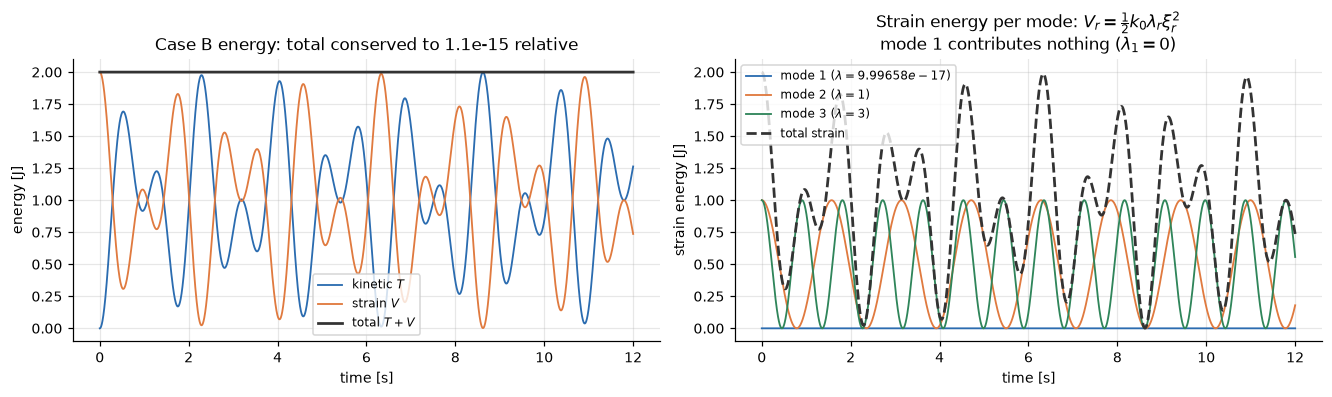

total energy: mean 2.000000 J, peak-to-peak 2.220e-15 J
initial strain energy 1/2 q0' k q0 = 2.000000 J


In [17]:
# --- energy bookkeeping: kinetic, strain, and their conserved sum ----------
def energies(Q, V, Lmat):
    KE = 0.5 * M0 * np.sum(V ** 2, axis=0)                       # [J]
    PE = 0.5 * K0 * np.einsum("it,ij,jt->t", Q, Lmat, Q)         # [J]
    return KE, PE

Vmod_B = U_f @ np.vstack([  # modal velocities, differentiated analytically
    (-(U_f.T @ Q0_LOCAL)[r] * om_f[r] * np.sin(om_f[r] * t_grid)) if om_f[r] > 1e-12
    else np.zeros_like(t_grid) for r in range(N)])
KE, PE = energies(Q_B, Vmod_B, Lfree)
tot = KE + PE

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(t_grid, KE, lw=1.2, color=C_LINE, label="kinetic $T$")
axes[0].plot(t_grid, PE, lw=1.2, color=C_ORANGE, label="strain $V$")
axes[0].plot(t_grid, tot, lw=1.8, color="0.2", label="total $T+V$")
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("energy [J]")
axes[0].set_title(f"Case B energy: total conserved to "
                  f"{np.ptp(tot)/tot.mean():.1e} relative")
axes[0].legend(fontsize=8)

for r in range(N):
    axes[1].plot(t_grid, 0.5 * K0 * lam_f[r] * XI_B[r] ** 2, lw=1.2,
                 color=MODE_COLORS[r], label=f"mode {r+1} ($\\lambda={lam_f[r]:g}$)")
axes[1].plot(t_grid, PE, lw=1.8, color="0.2", ls="--", label="total strain")
axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("strain energy [J]")
axes[1].set_title("Strain energy per mode: $V_r=\\frac{1}{2} k_0\\lambda_r\\xi_r^2$\n"
                  "mode 1 contributes nothing ($\\lambda_1=0$)")
axes[1].legend(fontsize=8)
plt.show()

print(f"total energy: mean {tot.mean():.6f} J, peak-to-peak {np.ptp(tot):.3e} J")
print(f"initial strain energy 1/2 q0' k q0 = {0.5*Q0_LOCAL @ (K0*Lfree) @ Q0_LOCAL:.6f} J")

---
## 5. A Dirac impulse: a kick, then free motion

Start from rest and strike the system with a localised impulse

$$\mathbf{F}(t) \;=\; \mathbf{J}\,\delta(t-t_0), \qquad \mathbf{J}\ \text{in N·s}.$$

Handout 6 p. 2 gives the delta's defining property: it is zero except at one instant, and
$\int_{-\infty}^{\infty}\delta(t-\tau)\,dt=1$ — **unit area, not unit height**. That is what makes
$\mathbf{J}$ an impulse with units of N·s rather than a force in N.

Integrating $\mathbf{m}\ddot{\mathbf{q}}+\mathbf{k}\mathbf{q}=\mathbf{J}\delta(t-t_0)$ across the
instant, the finite $\mathbf{k}\mathbf{q}$ term contributes nothing over zero duration, so

$$\boxed{\;\Delta\dot{\mathbf{q}} \;=\; \mathbf{m}^{-1}\mathbf{J}\;}\qquad\text{with } \mathbf{q}\ \text{continuous.}$$

> ⚠️ **Do not implement a delta as a one-sample force spike.** A spike of height $F$ lasting one time
> step $\Delta t$ delivers impulse $F\Delta t$, so the answer silently depends on your grid. We apply
> the exact jump above and integrate freely on either side, which is grid-independent and matches the
> analytic result to solver precision.

Transforming into modal coordinates, $\Xi_r=\phi_r^\top\mathbf{J}\,\delta(t-t_0)$, and the handout's
unit impulse response (p. 2), scaled by the generalised mass, gives for $s=t-t_0\ge0$

$$\xi_r(t) \;=\; \frac{\phi_r^\top\mathbf{J}}{M_r\,\omega_r}\,\sin(\omega_r s),
\qquad\text{with the } \omega_r\to0 \text{ limit } \ \frac{\phi_r^\top\mathbf{J}}{M_r}\,s .$$

The factor $\phi_r^\top\mathbf{J}$ — the **GFT of the impulse pattern** — decides how much of each
mode the blow excites. A load orthogonal to a mode shape cannot excite that mode at all.


In [18]:
def modal_impulse(t, J, t0, U, omega, Mr, tol=1e-12):
    """xi_r(t) after an impulse J [N.s] applied at t0; zero before the kick."""
    s = np.maximum(t - t0, 0.0)
    XI = np.zeros((len(omega), len(t)))
    for r, w in enumerate(omega):
        g = U[:, r] @ J                      # generalised impulse of mode r  [N.s]
        XI[r] = (g / (Mr[r] * w)) * np.sin(w * s) if w > tol else (g / Mr[r]) * s
    XI[:, t < t0] = 0.0
    return XI

def direct_impulse(t, J, t0, Lmat):
    """Reference: rest, then an exact velocity jump at t0, then free integration."""
    Q = np.zeros((N, len(t))); V = np.zeros((N, len(t)))
    after = t >= t0
    t_a = t[after] - t0
    y0 = np.concatenate([np.zeros(N), J / M0])          # dq = 0, dv = m^-1 J
    def rhs(_, y):
        return np.concatenate([y[N:], -(K0 / M0) * (Lmat @ y[:N])])
    s = solve_ivp(rhs, (0.0, t_a[-1]), y0, t_eval=t_a, rtol=1e-11, atol=1e-13, method="DOP853")
    Q[:, after], V[:, after] = s.y[:N], s.y[N:]
    return Q, V

Mr_eq = M0 * np.ones(N)                 # equal masses, Euclidean-unit modes
XI_imp_f = modal_impulse(t_grid, J_VEC, T_KICK, U_f, om_f, Mr_eq)
Q_imp_f = U_f @ XI_imp_f
Qd_imp_f, Vd_imp_f = direct_impulse(t_grid, J_VEC, T_KICK, Lfree)

print(f"impulse J = {J_VEC} N.s applied to node 3 at t0 = {T_KICK} s")
print(f"  velocity jump  m^-1 J = {J_VEC/M0} m/s")
print(f"  modal impulse phi_r' J = {np.round(U_f.T @ J_VEC, 6)} N.s")
print(f"     -> mode 1 (translation) gets {U_f[:,0] @ J_VEC:.4f}, so the chain will DRIFT")
print(f"  modal vs direct integration: max |q diff| = {np.abs(Q_imp_f - Qd_imp_f).max():.2e} m")
print(f"  displacement continuous at the kick: |q(t0)| = {np.abs(Q_imp_f[:, np.searchsorted(t_grid, T_KICK)]).max():.2e} m")

impulse J = [0. 0. 1.] N.s applied to node 3 at t0 = 0.5 s
  velocity jump  m^-1 J = [0. 0. 1.] m/s
  modal impulse phi_r' J = [ 0.57735  -0.707107 -0.408248] N.s
     -> mode 1 (translation) gets 0.5774, so the chain will DRIFT
  modal vs direct integration: max |q diff| = 4.17e-11 m
  displacement continuous at the kick: |q(t0)| = 0.00e+00 m


In [19]:
display(animate_response(t_grid, Q_imp_f, XI_imp_f,
                         f"Free chain: impulse {J_VEC} N$\\cdot$s on node 3 at $t_0={T_KICK}$ s",
                         Lfree, U_f))

grounded: modal vs direct max |q diff| = 1.19e-11 m
  modal impulses phi_r' J = [ 0.736976 -0.591009 -0.327985] N.s  (no zero-frequency mode)


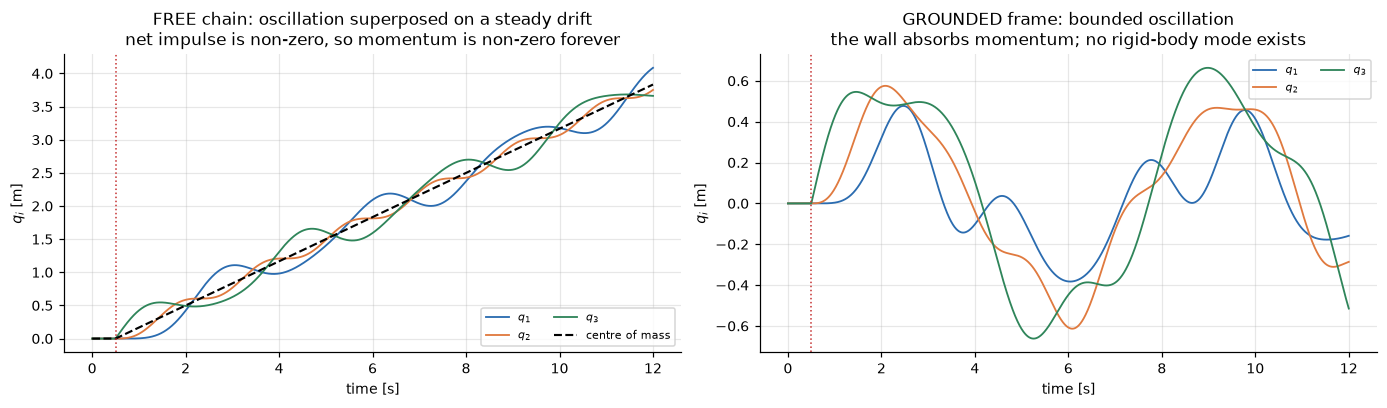


centre-of-mass velocity after the kick: 0.333333 m/s
predicted  sum(J) / (N m0) = 0.333333 m/s
the drift is entirely mode 1: xi_1(t) = (u_1'J / m0)(t-t0), slope 0.5774 m/s


In [20]:
# --- the same kick on the grounded frame -----------------------------------
XI_imp_g = modal_impulse(t_grid, J_VEC, T_KICK, U_g, om_g, Mr_eq)
Q_imp_g = U_g @ XI_imp_g
Qd_imp_g, _ = direct_impulse(t_grid, J_VEC, T_KICK, Lgnd)
print(f"grounded: modal vs direct max |q diff| = {np.abs(Q_imp_g - Qd_imp_g).max():.2e} m")
print(f"  modal impulses phi_r' J = {np.round(U_g.T @ J_VEC, 6)} N.s  (no zero-frequency mode)")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), sharex=True)
for i in range(N):
    axes[0].plot(t_grid, Q_imp_f[i], lw=1.2, color=MODE_COLORS[i], label=f"$q_{i+1}$")
    axes[1].plot(t_grid, Q_imp_g[i], lw=1.2, color=MODE_COLORS[i], label=f"$q_{i+1}$")
com = Q_imp_f.mean(axis=0)
axes[0].plot(t_grid, com, "k--", lw=1.4, label="centre of mass")
axes[0].set_title("FREE chain: oscillation superposed on a steady drift\n"
                  "net impulse is non-zero, so momentum is non-zero forever")
axes[1].set_title("GROUNDED frame: bounded oscillation\n"
                  "the wall absorbs momentum; no rigid-body mode exists")
for ax in axes:
    ax.axvline(T_KICK, color=C_RED, lw=1.0, ls=":")
    ax.set_xlabel("time [s]"); ax.set_ylabel("$q_i$ [m]"); ax.legend(fontsize=7.5, ncol=2)
plt.show()

slope = (U_f[:, 0] @ J_VEC) * U_f[0, 0] / M0
print(f"\ncentre-of-mass velocity after the kick: {np.gradient(com, t_grid)[-1]:.6f} m/s")
print(f"predicted  sum(J) / (N m0) = {J_VEC.sum()/(N*M0):.6f} m/s")
print(f"the drift is entirely mode 1: xi_1(t) = (u_1'J / m0)(t-t0), slope {(U_f[:,0]@J_VEC)/M0:.4f} m/s")

The free chain rings **and walks away**: a net impulse of $\sum_i J_i = 1$ N·s gives the whole
three-kilogram system a centre-of-mass velocity of $1/3$ m/s, which never decays because nothing
resists uniform translation. In modal terms the drift is exactly the $\lambda_1=0$ coefficient
growing linearly, while $\xi_2$ and $\xi_3$ oscillate about zero. The grounded frame has no such
mode, so its response is bounded.

**Which modes does a load excite?** Only those with $\phi_r^\top\mathbf{J}\neq0$. Two useful
consequences: a load applied at a node where a mode has a **zero** cannot excite it, and a load whose
spatial pattern *is* a mode shape excites that mode alone.


In [21]:
print("Selectivity of the load pattern -- modal impulses phi_r' J [N.s], free chain:\n")
print(f"{'impulse pattern J':>28}{'  mode 1':>10}{'  mode 2':>10}{'  mode 3':>10}   comment")
cases = [
    (np.array([0.0, 1.0, 0.0]), "hits the node where u_2 = 0"),
    (np.array([1.0, 0.0, -1.0]), "J is proportional to u_2"),
    (np.array([1.0, 1.0, 1.0]), "J is proportional to u_1"),
    (J_VEC, "single node, generic"),
]
for J, note in cases:
    g = U_f.T @ J
    print(f"{str(J):>28}" + "".join(f"{v:10.4f}" for v in g) + f"   {note}")
print("\n- A blow at the centre cannot excite mode 2, whose shape has a node there.")
print("- A blow shaped like u_2 excites mode 2 and NOTHING else: pure single-frequency ringing.")
print("- A uniform blow excites only mode 1: pure translation, no vibration at all.")

Selectivity of the load pattern -- modal impulses phi_r' J [N.s], free chain:

           impulse pattern J    mode 1    mode 2    mode 3   comment
                  [0. 1. 0.]    0.5774   -0.0000    0.8165   hits the node where u_2 = 0
               [ 1.  0. -1.]   -0.0000    1.4142    0.0000   J is proportional to u_2
                  [1. 1. 1.]    1.7321   -0.0000    0.0000   J is proportional to u_1
                  [0. 0. 1.]    0.5774   -0.7071   -0.4082   single node, generic

- A blow at the centre cannot excite mode 2, whose shape has a node there.
- A blow shaped like u_2 excites mode 2 and NOTHING else: pure single-frequency ringing.
- A uniform blow excites only mode 1: pure translation, no vibration at all.


---
## 6. Sustained forcing, Duhamel's integral, and resonance

Now use the **grounded** frame — a structure, not a floating chain — starting from rest, and drive it
with

$$\mathbf{F}(t) \;=\; F_0\,b\,\sin(\Omega t),$$

where $b$ is a dimensionless spatial pattern. We begin with $b=e_3$: a lateral load applied at roof
level.

Handout 6 p. 3 gives the general response to an arbitrary forcing as Duhamel's (convolution)
integral plus the initial-condition terms; in modal form (p. 5) this reads

$$\xi_r(t) \;=\; \underbrace{\xi_r(0)\cos\omega_r t+\frac{\dot\xi_r(0)}{\omega_r}\sin\omega_r t}_{\text{free / starting transient}} \;+\; \frac{1}{M_r\omega_r}\int_0^t \Xi_r(\tau)\,\sin[\omega_r(t-\tau)]\,d\tau .$$

Expanding $\sin[\omega_r(t-\tau)]$ turns the convolution into two running integrals that can be
evaluated once for the whole time grid, which is how the code below does it.

> ⚠️ **Undamped starting transients never decay.** With $\zeta=0$ there is no mechanism to remove the
> free part, so even "steady-state" responses here are a permanent superposition of $\Omega$ and
> $\omega_r$ components. Handout 6 p. 3 labels these terms "starting transient" and "steady state";
> the first word is only accurate once damping exists, which we add at the end of this section.


In [22]:
def duhamel(t, Xi_r, omega_r, Mr, tol=1e-12):
    """(1/(M w)) int_0^t Xi(tau) sin[w(t-tau)] dtau, evaluated on the whole grid at once."""
    if omega_r < tol:                                  # rigid-body mode: integrate twice
        first = cumulative_trapezoid(Xi_r, t, initial=0.0)
        return cumulative_trapezoid(first, t, initial=0.0) / Mr
    c = cumulative_trapezoid(Xi_r * np.cos(omega_r * t), t, initial=0.0)
    s = cumulative_trapezoid(Xi_r * np.sin(omega_r * t), t, initial=0.0)
    return (np.sin(omega_r * t) * c - np.cos(omega_r * t) * s) / (Mr * omega_r)

def forced_modal(t, Fmat, U, omega, Mr, q0=None, v0=None):
    """Full modal response: free part from initial conditions + Duhamel particular part."""
    q0 = np.zeros(N) if q0 is None else q0
    v0 = np.zeros(N) if v0 is None else v0
    XI_free = modal_free(t, q0, v0, U, omega)
    XI = np.zeros_like(XI_free)
    for r in range(len(omega)):
        Xi_r = U[:, r] @ Fmat                          # generalised force history [N]
        XI[r] = XI_free[r] + duhamel(t, Xi_r, omega[r], Mr[r])
    return XI

def direct_forced(t, Fmat, Lmat, q0=None, v0=None):
    """Reference: integrate m q'' + k q = F(t) in nodal coordinates."""
    q0 = np.zeros(N) if q0 is None else q0
    v0 = np.zeros(N) if v0 is None else v0
    from scipy.interpolate import interp1d
    Fi = interp1d(t, Fmat, axis=1, kind="cubic", assume_sorted=True)
    def rhs(tt, y):
        return np.concatenate([y[N:], (Fi(min(tt, t[-1])) - K0 * (Lmat @ y[:N])) / M0])
    s = solve_ivp(rhs, (t[0], t[-1]), np.concatenate([q0, v0]),
                  t_eval=t, rtol=1e-10, atol=1e-12, method="DOP853")
    return s.y[:N], s.y[N:]

# sanity: Duhamel against a closed form for a non-resonant single oscillator
w_test, Om_test = om_g[1], 0.7 * om_g[1]
Xi_test = F0 * np.sin(Om_test * t_grid)
num = duhamel(t_grid, Xi_test, w_test, M0)
ana = (F0 / (M0 * (w_test**2 - Om_test**2))) * (np.sin(Om_test*t_grid)
                                                - (Om_test/w_test)*np.sin(w_test*t_grid))
print(f"Duhamel check (Omega = 0.7 omega_2): max |numeric - analytic| = "
      f"{np.abs(num - ana).max():.2e} m")

Duhamel check (Omega = 0.7 omega_2): max |numeric - analytic| = 3.53e-06 m


In [23]:
OM_LOW = 0.35 * om_g[0]          # well below the first natural frequency
OM_NEAR = 0.93 * om_g[0]         # near resonance with mode 1
OM_RES = om_g[0]                 # exactly resonant with mode 1

def force_history(t, b, Omega, amp=F0):
    return amp * np.outer(b, np.sin(Omega * t))          # (N, T) in newtons

results_forced = {}
for tag, Om in [("low  $\\Omega=0.35\\,\\omega_1$", OM_LOW),
                ("near $\\Omega=0.93\\,\\omega_1$", OM_NEAR),
                ("exact $\\Omega=\\omega_1$", OM_RES)]:
    Fm = force_history(t_grid, B_ROOF, Om)
    XI = forced_modal(t_grid, Fm, U_g, om_g, Mr_eq)
    Q = U_g @ XI
    Qd, _ = direct_forced(t_grid, Fm, Lgnd)
    results_forced[tag] = dict(Om=Om, XI=XI, Q=Q, Qd=Qd, F=Fm)
    print(f"{tag:26s} Omega={Om:.4f} rad/s   max|q| = {np.abs(Q).max():7.4f} m   "
          f"modal-vs-direct {np.abs(Q - Qd).max():.2e} m")

# At exact resonance the closed form is the limiting solution, not a division by zero:
#   xi(t) = (A / (2 M w^2)) ( sin(w t) - w t cos(w t) )     for xi(0)=xi'(0)=0
A_res = U_g[:, 0] @ (F0 * B_ROOF)
w1 = om_g[0]
xi_limit = (A_res / (2 * M0 * w1**2)) * (np.sin(w1*t_grid) - w1*t_grid*np.cos(w1*t_grid))
print(f"\nexact resonance, mode 1: limiting solution vs Duhamel -> max |diff| = "
      f"{np.abs(xi_limit - results_forced['exact $\\Omega=\\omega_1$']['XI'][0]).max():.2e} m")
print("  amplitude grows linearly in t (the -w t cos(w t) term); nothing is divided by zero")

low  $\Omega=0.35\,\omega_1$ Omega=0.3115 rad/s   max|q| =  1.1156 m   modal-vs-direct 1.94e-06 m
near $\Omega=0.93\,\omega_1$ Omega=0.8278 rad/s   max|q| =  3.2887 m   modal-vs-direct 2.92e-06 m


exact $\Omega=\omega_1$    Omega=0.8901 rad/s   max|q| =  3.2093 m   modal-vs-direct 3.35e-06 m

exact resonance, mode 1: limiting solution vs Duhamel -> max |diff| = 3.07e-06 m
  amplitude grows linearly in t (the -w t cos(w t) term); nothing is divided by zero


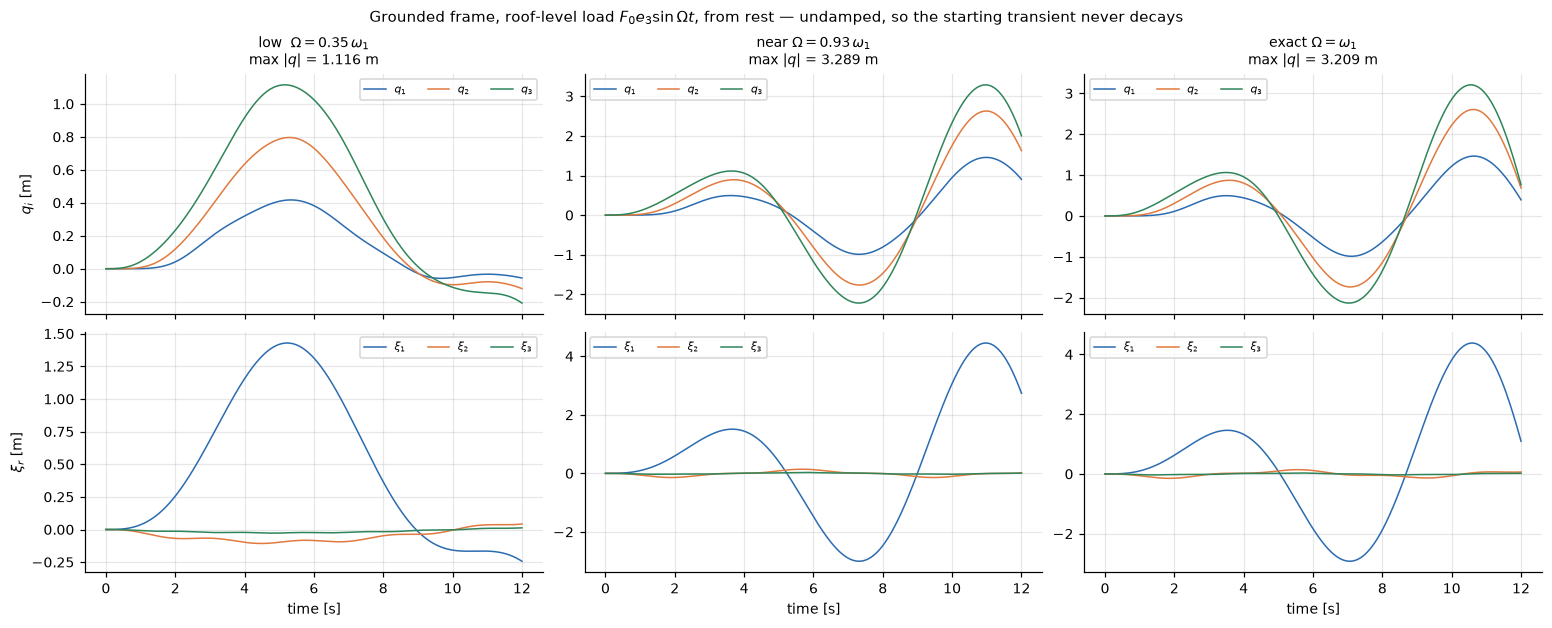

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(14, 5.6), sharex=True)
for c, (tag, d) in enumerate(results_forced.items()):
    for i in range(N):
        axes[0, c].plot(t_grid, d["Q"][i], lw=1.0, color=MODE_COLORS[i], label=f"$q_{i+1}$")
    axes[0, c].set_title(f"{tag}\nmax $|q|$ = {np.abs(d['Q']).max():.3f} m", fontsize=9)
    for r in range(N):
        axes[1, c].plot(t_grid, d["XI"][r], lw=1.0, color=MODE_COLORS[r],
                        label=f"$\\xi_{r+1}$")
    axes[1, c].set_xlabel("time [s]")
    if c == 0:
        axes[0, c].set_ylabel("$q_i$ [m]"); axes[1, c].set_ylabel("$\\xi_r$ [m]")
    axes[0, c].legend(fontsize=7, ncol=3); axes[1, c].legend(fontsize=7, ncol=3)
fig.suptitle("Grounded frame, roof-level load $F_0 e_3\\sin\\Omega t$, from rest — "
             "undamped, so the starting transient never decays", fontsize=10)
plt.show()

In [25]:
display(animate_response(t_grid, results_forced["exact $\\Omega=\\omega_1$"]["Q"],
                         results_forced["exact $\\Omega=\\omega_1$"]["XI"],
                         "Exact resonance with mode 1: amplitude grows linearly in $t$",
                         Lgnd, U_g, grounded=True))

At low $\Omega$ the frame simply follows the load quasi-statically. Near resonance the amplitude
grows large and beats between $\Omega$ and $\omega_1$. **At exact resonance the envelope grows
without bound, linearly in $t$** — the $-\omega_1 t\cos\omega_1 t$ term — which is the honest form of
"the dynamic magnification factor goes to infinity" (Handout 6 p. 3). Nothing here divides by zero:
the resonant case has its own limiting solution, and the Duhamel integral reproduces it.

Notice which coefficient blows up: only $\xi_1$. The other two modes are driven off-resonance and
stay bounded. **Resonance is a property of one mode at a time.**

### Isolating a mode with the load pattern

Choose $b=u_2$ instead of $e_3$. Then $\Xi_r=F_0\,u_r^\top u_2\sin\Omega t=F_0\delta_{r2}\sin\Omega t$:
only mode 2 is driven at all.


load pattern b = u_2, driven at Omega = omega_2 = 2.4940 rad/s
  generalised forces u_r' b = [-0.  1.  0.]   <- a clean selector
  max |xi_r| over the run  = [0.       2.272886 0.      ] m
  modes 1 and 3 stay at exactly zero: they are never driven and started at rest.


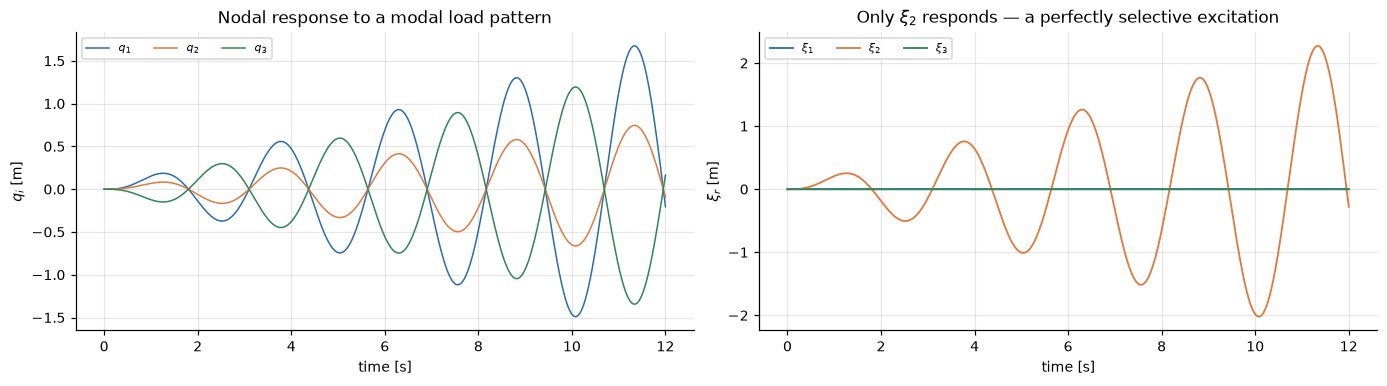

In [26]:
Fm_mode = force_history(t_grid, U_g[:, 1], om_g[1])     # pattern = u_2, driven at omega_2
XI_mode = forced_modal(t_grid, Fm_mode, U_g, om_g, Mr_eq)
Q_mode = U_g @ XI_mode
print(f"load pattern b = u_2, driven at Omega = omega_2 = {om_g[1]:.4f} rad/s")
print(f"  generalised forces u_r' b = {np.round(U_g.T @ U_g[:, 1], 12)}   <- a clean selector")
print(f"  max |xi_r| over the run  = {np.round(np.abs(XI_mode).max(axis=1), 6)} m")
print("  modes 1 and 3 stay at exactly zero: they are never driven and started at rest.")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.4), sharex=True)
for i in range(N):
    axes[0].plot(t_grid, Q_mode[i], lw=1.0, color=MODE_COLORS[i], label=f"$q_{i+1}$")
for r in range(N):
    axes[1].plot(t_grid, XI_mode[r], lw=1.2, color=MODE_COLORS[r], label=f"$\\xi_{r+1}$")
axes[0].set_title("Nodal response to a modal load pattern"); axes[0].set_ylabel("$q_i$ [m]")
axes[1].set_title("Only $\\xi_2$ responds — a perfectly selective excitation")
axes[1].set_ylabel("$\\xi_r$ [m]")
for ax in axes:
    ax.set_xlabel("time [s]"); ax.legend(fontsize=7.5, ncol=3)
plt.show()

### Extension: light modal damping

Everything so far was undamped, which is why resonance grew without limit. Add a small amount of
damping **prescribed mode by mode**:

$$\ddot\xi_r + 2\zeta_r\omega_r\dot\xi_r + \omega_r^2\xi_r \;=\; \frac{\Xi_r(t)}{M_r}.$$

> ⚠️ **This is a modelling choice, not a derivation.** Writing damping directly in modal coordinates
> assumes the damping matrix is diagonalised by the *undamped* modes — so-called classical or
> Rayleigh damping. A general $\mathbf{c}$ does **not** decouple in $\Phi$, and then the modes become
> complex and the tidy correspondence with the real Laplacian eigenvectors breaks. We use $\zeta_r$
> because it is the standard light-damping idealisation, and we say so rather than implying that
> every damped structure behaves this way.

With damping the starting transient genuinely decays and the resonant response saturates at the
steady amplitude

$$|\xi_r|_{\text{ss}} \;=\; \frac{\Xi_0/M_r}{\sqrt{(\omega_r^2-\Omega^2)^2+(2\zeta_r\omega_r\Omega)^2}} \;\xrightarrow[\ \Omega=\omega_r\ ]{}\; \frac{\Xi_0}{M_r\,2\zeta_r\omega_r^2}.$$


In [27]:
def damped_modal(t, Fmat, U, omega, Mr, zeta):
    """Integrate xi'' + 2 z w xi' + w^2 xi = Xi/M for each mode (from rest)."""
    from scipy.interpolate import interp1d
    XI = np.zeros((len(omega), len(t)))
    for r, w in enumerate(omega):
        Xi_r = interp1d(t, U[:, r] @ Fmat, kind="cubic", assume_sorted=True)
        def rhs(tt, y, w=w, Xi_r=Xi_r, Mr_r=Mr[r]):
            return [y[1], Xi_r(min(tt, t[-1]))/Mr_r - 2*zeta*w*y[1] - w**2*y[0]]
        s = solve_ivp(rhs, (t[0], t[-1]), [0.0, 0.0], t_eval=t,
                      rtol=1e-10, atol=1e-12, method="DOP853")
        XI[r] = s.y[0]
    return XI

# The damped transient decays with time constant 1/(zeta*omega_1). At zeta = 0.05 and
# omega_1 = 0.89 rad/s that is ~22 s -- LONGER than the 12 s used everywhere else, so on
# the standard grid the damped and undamped curves are still almost identical. To show
# genuine saturation we integrate this one case over several decay constants.
TAU_DECAY = 1.0 / (ZETA * om_g[0])
T_DAMP = 6.0 * TAU_DECAY
t_damp = np.linspace(0.0, T_DAMP, 4001)
print(f"decay time constant 1/(zeta*omega_1) = {TAU_DECAY:.1f} s")
print(f"  -> the standard T_END = {T_END} s is only {T_END/TAU_DECAY:.2f} time constants;")
print(f"     this demonstration runs to {T_DAMP:.0f} s ({T_DAMP/TAU_DECAY:.0f} constants).")

Fm_res_long = force_history(t_damp, B_ROOF, OM_RES)
XI_damped = damped_modal(t_damp, Fm_res_long, U_g, om_g, Mr_eq, ZETA)
Q_damped = U_g @ XI_damped
XI_undamped_long = forced_modal(t_damp, Fm_res_long, U_g, om_g, Mr_eq)

ss_pred = (U_g[:, 0] @ (F0 * B_ROOF)) / (M0 * 2 * ZETA * om_g[0] ** 2)
late = t_damp > 0.7 * T_DAMP
print(f"\nzeta = {ZETA};  at exact resonance with mode 1")
print(f"  predicted steady amplitude |xi_1| = {ss_pred:.6f} m")
print(f"  observed late-time amplitude      = {np.abs(XI_damped[0, late]).max():.6f} m")
print(f"  undamped |xi_1| at the same time  = {np.abs(XI_undamped_long[0, late]).max():.6f} m"
      f"  (still growing linearly)")

decay time constant 1/(zeta*omega_1) = 22.5 s
  -> the standard T_END = 12.0 s is only 0.53 time constants;
     this demonstration runs to 135 s (6 constants).



zeta = 0.05;  at exact resonance with mode 1
  predicted steady amplitude |xi_1| = 9.302330 m
  observed late-time amplitude      = 9.278512 m
  undamped |xi_1| at the same time  = 55.522777 m  (still growing linearly)


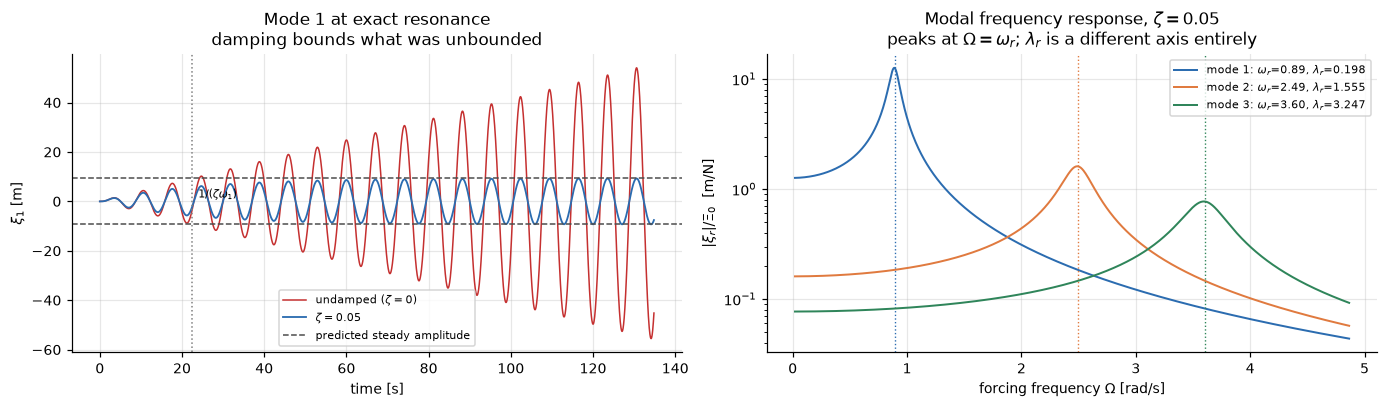

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
axes[0].plot(t_damp, XI_undamped_long[0], lw=1.0, color=C_RED, label="undamped ($\\zeta=0$)")
axes[0].plot(t_damp, XI_damped[0], lw=1.2, color=C_LINE, label=f"$\\zeta={ZETA}$")
axes[0].axvline(TAU_DECAY, color="0.5", ls=":", lw=1.0)
axes[0].annotate("$1/(\\zeta\\omega_1)$", (TAU_DECAY, 0.0), fontsize=7,
                 xytext=(4, 2), textcoords="offset points")
axes[0].axhline(ss_pred, color="0.3", ls="--", lw=1.0, label="predicted steady amplitude")
axes[0].axhline(-ss_pred, color="0.3", ls="--", lw=1.0)
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("$\\xi_1$ [m]")
axes[0].set_title("Mode 1 at exact resonance\ndamping bounds what was unbounded")
axes[0].legend(fontsize=7.5)

Om_scan = np.linspace(0.02, 1.35 * om_g[-1], 800)
for r in range(N):
    H = 1.0 / (M0 * np.sqrt((om_g[r]**2 - Om_scan**2)**2 + (2*ZETA*om_g[r]*Om_scan)**2))
    axes[1].plot(Om_scan, H, lw=1.3, color=MODE_COLORS[r],
                 label=f"mode {r+1}: $\\omega_r$={om_g[r]:.2f}, $\\lambda_r$={lam_g[r]:.3f}")
    axes[1].axvline(om_g[r], color=MODE_COLORS[r], ls=":", lw=0.9)
axes[1].set_xlabel("forcing frequency $\\Omega$ [rad/s]")
axes[1].set_ylabel("$|\\xi_r| / \\Xi_0$  [m/N]")
axes[1].set_yscale("log")
axes[1].set_title(f"Modal frequency response, $\\zeta={ZETA}$\n"
                  "peaks at $\\Omega=\\omega_r$; $\\lambda_r$ is a different axis entirely")
axes[1].legend(fontsize=7.5)
plt.show()

> ⚠️ **$\Omega$ and $\lambda_r$ answer different questions.** The horizontal axis above is the
> **temporal** forcing frequency $\Omega$, in rad/s — how fast the load shakes. The graph frequency
> $\lambda_r$ is dimensionless and describes **spatial** variation across springs; it enters only
> through $\omega_r=\sqrt{k_0\lambda_r/m_0}$, which sets *where* each resonant peak sits. A signal
> can be spatially smooth (low $\lambda$) while oscillating rapidly in time (high $\Omega$), and
> vice versa. Confusing the two is the commonest error when structural people meet graph signal
> processing, and it is why this notebook labels every axis with its units.


---
## 7. The correspondence, its scope, and verification

### The practical dictionary

| Structural dynamics question | Graph signal processing answer | Where it appeared |
|---|---|---|
| Free vibration from initial conditions | **modal decomposition** = GFT of the initial state, each coefficient evolving at its own $\omega_r$ | §4 |
| Impulse response | **mode excitation** weighted by $\phi_r^\top\mathbf{J}$, the GFT of the load pattern | §5 |
| Sustained forcing | **dynamic spectral response**: each graph frequency is a band-pass filter peaking at $\omega_r=\sqrt{k_0\lambda_r/m_0}$ | §6 |
| Which loads excite which motion | a load orthogonal to a mode cannot excite it; $\hat{F}_r=0\Rightarrow$ no response in mode $r$ | §5 |
| Static stiffness | $\hat{F}_r=k_0\lambda_r\hat{x}_r$ — mode by mode, force equals graph frequency times displacement | §3 |

Two further connections worth naming, because they are the reason a graph person should care:

**Weak couplings become communities.** If two clusters of masses are stiffly connected internally
and joined by one soft spring, the Laplacian has a small $\lambda_2$ and its Fiedler vector splits
the clusters — which mechanically is a low-frequency mode in which the two blocks move as near-rigid
bodies against each other. Spectral clustering and "the lowest sway mode" are the same computation.

**Modal attenuation is graph denoising.** A low-pass graph filter multiplies $\hat{x}_r$ by a
decreasing function of $\lambda_r$; a structure driven well below its first natural frequency does
exactly that, responding almost entirely in its smoothest modes. The heat-kernel filter
$e^{-\tau\lambda}$ of Lesson 2 and the dynamic magnification factor of Handout 6 p. 3 are both
functions applied to the spectrum.

### Scope — what this does *not* license

- **Undirected, non-negative, scalar.** One displacement per node and $w_{ij}=w_{ji}\ge0$. A negative
  stiffness would destroy positive semidefiniteness and with it the real non-negative $\lambda_r$
  that make $\omega_r$ real.
- **Equal masses, or a modified inner product.** With $\mathbf{m}\ne m_0I$ the modes are
  $\mathbf{m}$-orthogonal, the coefficients are $\phi_r^\top\mathbf{m}\mathbf{q}/M_r$, and they are
  **not** the ordinary GFT of $\mathbf{q}$ (§2 sidebar).
- **Not general frames.** Real structures have beams, joints, rotations, and several degrees of
  freedom per node. Their stiffness matrices are assembled from element matrices that encode geometry
  and orientation, and are not $k_0L$ for any graph Laplacian.
- **The Laplacian alone is not a dynamic model.** $L$ fixes neither $\mathbf{m}$ nor time. Given only
  a graph you can compute a GFT; to get $\omega_r$ you must additionally supply masses and a
  stiffness scale. This is why Lessons 1–4 could do spectral analysis on karate clubs and weather
  stations without any dynamics at all — and why nothing there had a natural frequency.
- **Classical damping is an assumption.** §6's $\zeta_r$ presumes the damping matrix is diagonalised
  by the undamped modes. A general $\mathbf{c}$ gives complex modes and breaks the correspondence
  with the real Laplacian eigenvectors.

### Verification


In [29]:
tol = 1e-9
checks = []
def check(name, ok, detail=""):
    checks.append((name, bool(ok), detail))

# ---------- assembly ------------------------------------------------------
check("element assembly reproduces k = k0 * L exactly",
      np.array_equal(k_assembled, K0 * Lfree))
check("L is symmetric with zero row sums (ordinary Laplacian)",
      np.array_equal(Lfree, Lfree.T) and np.abs(Lfree @ np.ones(N)).max() < tol)
check("L is positive semidefinite", np.linalg.eigvalsh(Lfree).min() > -tol,
      f"min eig {np.linalg.eigvalsh(Lfree).min():.2e}")
check("grounded L_g equals the 4-node Laplacian with the wall removed",
      np.array_equal(L4[1:, 1:], Lgnd))
check("L_g rows do NOT sum to zero (it is grounded, not an ordinary Laplacian)",
      np.abs(Lgnd @ np.ones(N)).max() > 0.5,
      f"L_g @ 1 = {Lgnd @ np.ones(N)}")
check("strain energy: edge sum == quadratic form",
      np.isclose(V_edges, V_matrix), f"{V_edges:.8f} vs {V_matrix:.8f} J")

# ---------- modes ---------------------------------------------------------
for tag, Lm, lam_, U_, om_ in [("free", Lfree, lam_f, U_f, om_f),
                               ("grounded", Lgnd, lam_g, U_g, om_g)]:
    res = max(np.abs(Lm @ U_[:, r] - lam_[r] * U_[:, r]).max() for r in range(N))
    check(f"[{tag}] eigenpair residual |L u - lam u|", res < tol, f"{res:.2e}")
    check(f"[{tag}] U is orthonormal", np.abs(U_.T @ U_ - np.eye(N)).max() < tol,
          f"{np.abs(U_.T @ U_ - np.eye(N)).max():.2e}")
    check(f"[{tag}] omega_r == sqrt(k0 lambda_r / m0)",
          np.allclose(om_, np.sqrt(K0 * lam_ / M0)))
    check(f"[{tag}] lambda_r == u_r' L u_r (Dirichlet form)",
          np.allclose(lam_, [U_[:, r] @ Lm @ U_[:, r] for r in range(N)]))
    check(f"[{tag}] modal decoupling: U' k U diagonal",
          np.abs((U_.T @ (K0*Lm) @ U_) - np.diag(np.diag(U_.T @ (K0*Lm) @ U_))).max() < tol)
check("free-chain eigenvalues are exactly (0, 1, 3)",
      np.allclose(lam_f, [0.0, 1.0, 3.0]), f"{np.round(lam_f, 12)}")
check("free-chain shapes proportional to (1,1,1), (1,0,-1), (1,-2,1)",
      all(np.isclose(abs(np.array(t_, float) @ U_f[:, r] / np.linalg.norm(t_)), 1.0)
          for r, t_ in enumerate([[1,1,1], [1,0,-1], [1,-2,1]])))
check("grounded has no zero-frequency mode", om_g.min() > 1e-6,
      f"min omega {om_g.min():.4f} rad/s")
check("grounded lambda_r == 4 sin^2((2r-1)pi/14)",
      np.allclose(lam_g, [4*np.sin((2*r-1)*np.pi/14)**2 for r in (1, 2, 3)]))

# ---------- GFT == modal transform ---------------------------------------
check("GFT reconstruction U U' x == x",
      np.abs(U_f @ (U_f.T @ x_snap) - x_snap).max() < tol,
      f"{np.abs(U_f @ (U_f.T @ x_snap) - x_snap).max():.2e} m")
check("Parseval ||x||^2 == sum xhat_r^2",
      np.isclose(x_snap @ x_snap, np.sum((U_f.T @ x_snap) ** 2)))
check("strain energy == (k0/2) sum lambda_r xhat_r^2",
      np.isclose(0.5 * x_snap @ (K0*Lfree) @ x_snap,
                 0.5 * K0 * np.sum(lam_f * (U_f.T @ x_snap) ** 2)))
check("generalised masses M_r all equal m0 (equal masses, unit-norm modes)",
      np.allclose(Mr_f, M0), f"{np.round(Mr_f, 12)} kg")
check("static force coefficients: Fhat_r == k0 lambda_r xhat_r",
      np.allclose(U_f.T @ (K0 * Lfree @ x_snap), K0 * lam_f * (U_f.T @ x_snap)))
check("uniform translation stores zero strain energy",
      np.isclose(0.5 * np.ones(N) @ (K0*Lfree) @ np.ones(N), 0.0))

# ---------- unequal masses ------------------------------------------------
check("unequal masses: Phi' m Phi == I (mass-orthonormal)",
      np.abs(Phi_u.T @ m_uneq @ Phi_u - np.eye(N)).max() < 1e-10)
check("unequal masses: Phi' Phi is NOT the identity",
      np.abs(Phi_u.T @ Phi_u - np.eye(N)).max() > 1e-3,
      f"max deviation {np.abs(Phi_u.T @ Phi_u - np.eye(N)).max():.3f}")
check("unequal masses: mass-weighted coords differ from the plain GFT",
      np.abs(xi_mass - gft_plain).max() > 1e-3,
      f"max difference {np.abs(xi_mass - gft_plain).max():.4f}")
check("unequal masses: Phi xi still reconstructs q",
      np.abs(Phi_u @ xi_mass - q_test).max() < 1e-10)

# ---------- free motion ---------------------------------------------------
check("case A modal == direct integration",
      np.abs(Q_A - Qd_A).max() < 1e-8, f"{np.abs(Q_A - Qd_A).max():.2e} m")
check("case A excites exactly one mode",
      int(np.sum(np.abs(U_f.T @ q0_mode) > 1e-10)) == 1)
check("case B modal == direct integration",
      np.abs(Q_B - Qd_B).max() < 1e-8, f"{np.abs(Q_B - Qd_B).max():.2e} m")
check("case B free-motion energy conserved",
      np.ptp(tot) / tot.mean() < 1e-6, f"relative drift {np.ptp(tot)/tot.mean():.2e}")
check("zero mode is linear in t, not sinusoidal",
      np.allclose(XI_B[0], (U_f.T @ Q0_LOCAL)[0] + (U_f.T @ V0_ZERO)[0] * t_grid))
check("zero-velocity release keeps the centre of mass fixed",
      np.ptp(Q_B.mean(axis=0)) < 1e-9, f"{np.ptp(Q_B.mean(axis=0)):.2e} m")

# ---------- impulse -------------------------------------------------------
k_kick = int(np.searchsorted(t_grid, T_KICK))
check("impulse: displacement is continuous across the kick",
      np.abs(Q_imp_f[:, k_kick]).max() < 1e-6,
      f"max |q(t0)| = {np.abs(Q_imp_f[:, k_kick]).max():.2e} m")
check("impulse: velocity jump equals m^-1 J",
      np.allclose(Vd_imp_f[:, k_kick], J_VEC / M0, atol=1e-6),
      f"{np.round(Vd_imp_f[:, k_kick], 6)} vs {J_VEC/M0} m/s")
check("impulse: free chain, modal == direct",
      np.abs(Q_imp_f - Qd_imp_f).max() < 1e-8, f"{np.abs(Q_imp_f - Qd_imp_f).max():.2e} m")
check("impulse: grounded, modal == direct",
      np.abs(Q_imp_g - Qd_imp_g).max() < 1e-8, f"{np.abs(Q_imp_g - Qd_imp_g).max():.2e} m")
check("impulse: system is at rest before t0",
      np.abs(Q_imp_f[:, t_grid < T_KICK]).max() < tol)
check("impulse: centre-of-mass velocity == sum(J)/(N m0)",
      np.isclose(np.gradient(Q_imp_f.mean(axis=0), t_grid)[-1], J_VEC.sum()/(N*M0), atol=1e-4))
check("impulse: a load orthogonal to a mode does not excite it",
      abs(U_f[:, 1] @ np.array([0.0, 1.0, 0.0])) < tol)
check("impulse: grounded frame does not drift",
      np.abs(Q_imp_g.mean(axis=0)[-1]) < np.abs(Q_imp_f.mean(axis=0)[-1]) / 10)

# ---------- forcing -------------------------------------------------------
check("Duhamel integral matches the closed form (non-resonant)",
      np.abs(num - ana).max() < 1e-5, f"{np.abs(num - ana).max():.2e} m")
for tag, d in results_forced.items():
    check(f"forced [{tag}] modal == direct integration",
          np.abs(d["Q"] - d["Qd"]).max() < 1e-4,
          f"{np.abs(d['Q'] - d['Qd']).max():.2e} m")
check("exact resonance matches the limiting solution",
      np.abs(xi_limit - results_forced["exact $\\Omega=\\omega_1$"]["XI"][0]).max() < 1e-4,
      f"{np.abs(xi_limit - results_forced['exact $\\Omega=\\omega_1$']['XI'][0]).max():.2e} m")
check("resonant amplitude grows (undamped)",
      np.abs(results_forced["exact $\\Omega=\\omega_1$"]["XI"][0][-200:]).max()
      > 3 * np.abs(results_forced["exact $\\Omega=\\omega_1$"]["XI"][0][:200]).max())
check("a modal load pattern excites only its own mode",
      np.abs(XI_mode[[0, 2]]).max() < 1e-8, f"max |xi_1|,|xi_3| = {np.abs(XI_mode[[0,2]]).max():.2e} m")
check("damping bounds the resonant response",
      np.abs(XI_damped[0]).max() < np.abs(XI_undamped_long[0]).max(),
      f"damped max {np.abs(XI_damped[0]).max():.3f} m vs undamped "
      f"{np.abs(XI_undamped_long[0]).max():.3f} m over the same window")
check("damped response has actually saturated",
      abs(np.abs(XI_damped[0, t_damp > 0.85*T_DAMP]).max()
          - np.abs(XI_damped[0, (t_damp > 0.55*T_DAMP) & (t_damp < 0.7*T_DAMP)]).max())
      < 0.05 * ss_pred)
check("damped steady amplitude matches Xi_0/(2 zeta M w^2)",
      np.isclose(np.abs(XI_damped[0, late]).max(), ss_pred, rtol=0.05),
      f"observed {np.abs(XI_damped[0, late]).max():.5f} vs predicted {ss_pred:.5f} m")

# ---------- report --------------------------------------------------------
width = max(len(n) for n, _, _ in checks)
for n, ok, d in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {n:<{width}}  {d}")
bad = [n for n, ok, _ in checks if not ok]
assert not bad, f"failed checks: {bad}"
print(f"\nAll {len(checks)} checks passed.")

PASS  element assembly reproduces k = k0 * L exactly                           
PASS  L is symmetric with zero row sums (ordinary Laplacian)                   
PASS  L is positive semidefinite                                               min eig 3.93e-17
PASS  grounded L_g equals the 4-node Laplacian with the wall removed           
PASS  L_g rows do NOT sum to zero (it is grounded, not an ordinary Laplacian)  L_g @ 1 = [1. 0. 0.]
PASS  strain energy: edge sum == quadratic form                                0.82000000 vs 0.82000000 J
PASS  [free] eigenpair residual |L u - lam u|                                  4.44e-16
PASS  [free] U is orthonormal                                                  7.77e-16
PASS  [free] omega_r == sqrt(k0 lambda_r / m0)                                 
PASS  [free] lambda_r == u_r' L u_r (Dirichlet form)                           
PASS  [free] modal decoupling: U' k U diagonal                                 
PASS  [grounded] eigenpair residual |L u -

### Check your understanding

<details>
<summary><b>1.</b> A colleague computes the Laplacian of a road network and reports "the natural
frequency of mode 2 is 0.47". What is wrong?</summary>

$\lambda_2$ is dimensionless — it is a graph frequency, a measure of variation across edges. A
natural frequency needs $\omega_2=\sqrt{k_0\lambda_2/m_0}$, which requires a **stiffness scale** and
a **mass**, neither of which a graph carries. A road network has no masses on its nodes and no
springs on its edges, so it has no natural frequencies at all. The number 0.47 is real and useful;
calling it a frequency in rad/s is a units error that the Laplacian cannot detect for you.
</details>

<details>
<summary><b>2.</b> The free chain's first mode has $\lambda_1=0$ and $\omega_1=0$. Is that a
degenerate case to be avoided?</summary>

No — it is the rigid-body freedom, and it is physically correct: an unsupported chain can translate
without stretching any spring. It needs separate treatment only in the *formulas*, because
$\xi_r(0)\cos\omega_r t+\dot\xi_r(0)\sin(\omega_r t)/\omega_r$ divides by $\omega_r$. The correct
solution there is $\xi_1(t)=\xi_1(0)+\dot\xi_1(0)t$, which §5 shows producing exactly the
centre-of-mass drift $\sum_iJ_i/(Nm_0)$ after an impulse. Grounding the structure removes the mode;
the constant vector leaves the null space because translation now stretches the ground spring.
</details>

<details>
<summary><b>3.</b> You are given a displacement snapshot $\mathbf{q}$ and compute
$\hat{F}_r=k_0\lambda_r\hat{x}_r$. Have you found the applied load?</summary>

Only if the structure is in **static** equilibrium. Dynamically the modal balance is
$\hat F_r = M_r\ddot\xi_r+M_r\omega_r^2\xi_r$ (plus $2M_r\zeta_r\omega_r\dot\xi_r$ when damped), so
the same shape at the same instant is consistent with a statically loaded structure, or with a freely
vibrating one carrying no external load at all and passing through that shape with large
acceleration. A single displacement snapshot cannot distinguish them; you need the velocity and
acceleration, or knowledge that the motion is static.
</details>

<details>
<summary><b>4.</b> Why does hitting the middle mass of the free chain never excite mode 2?</summary>

Because mode 2's shape $(1,0,-1)$ has a **node** at the centre: $u_2$'s middle entry is exactly zero,
so $\phi_2^\top\mathbf{J}=0$ for $\mathbf{J}=(0,J,0)$. The generalised force of a mode is the
projection of the load onto its shape, so a load applied only where a mode does not move does no work
on that mode. The graph reading is identical: the GFT coefficient of the load at that frequency is
zero, so there is no input to that channel.
</details>

<details>
<summary><b>5.</b> At exact resonance the dynamic magnification factor is $1/(1-\Omega^2/\omega^2)
\to\infty$. Does the simulation divide by zero?</summary>

No, and it must not. The DMF describes the *steady-state* amplitude of a bounded particular solution,
which ceases to exist at $\Omega=\omega_r$ — so the right object is the limiting solution
$\xi_r(t)=\frac{\Xi_0}{2M_r\omega_r^2}(\sin\omega_r t-\omega_r t\cos\omega_r t)$, whose envelope
grows **linearly in $t$** rather than being infinite at any instant. §6 verifies that the numerical
Duhamel integral reproduces this to $10^{-4}$ m. Adding any damping restores a finite steady
amplitude, $\Xi_0/(2M_r\zeta_r\omega_r^2)$.
</details>

<details>
<summary><b>6.</b> Two systems have the same Laplacian but different masses. Do they have the same
mode shapes and the same GFT?</summary>

Same GFT, different modes. The GFT is defined by $L$ alone, so $U$ and $\hat{x}=U^\top x$ are
identical. But the mode shapes solve $k_0L\phi=\omega^2\mathbf{m}\phi$, which depends on
$\mathbf{m}$: with unequal masses the modes are $\mathbf{m}$-orthogonal, are not the columns of $U$,
and their coefficients $\phi_r^\top\mathbf{m}\mathbf{q}/M_r$ are not $U^\top\mathbf{q}$. The §2
sidebar measures the gap. This is the precise sense in which "the Laplacian specifies neither the
masses nor the dynamics".
</details>

### References

- **[Lagace, *MIT 16.20 Handout 6, (Introduction to) Structural Dynamics*,
  2002](https://ocw.mit.edu/courses/16-20-structural-mechanics-fall-2002/35b10a9694157002e14893014de39058_ho6.pdf)**
  — pp. 1–3: the equation of motion $m_{ij}\ddot q_j+k_{ij}q_j=F_i$, free vibration and
  $\omega=\sqrt{k/m}$, the Dirac delta's unit-area property, the unit impulse response
  $q=\frac{1}{m\omega}\sin\omega(t-\tau)$, Duhamel's convolution integral with its initial-condition
  terms, and the sinusoidal response with its starting transient, steady state and dynamic
  magnification factor. pp. 4–5: the stiffness influence coefficient reading of $k_{ij}$ ("force at
  $i$ due to unit displacement at $j$"), the eigenproblem $|\mathbf{k}-\omega^2\mathbf{m}|=0$, modal
  orthogonality $\phi^{(r)\top}\mathbf{m}\phi^{(s)}=\delta_{rs}M_r$, and the normal equations
  $M_r\ddot\xi_r+M_r\omega_r^2\xi_r=\Xi_r$ with $M_r=\phi_r^\top\mathbf{m}\phi_r$ and
  $\Xi_r=\phi_r^\top\mathbf{F}$. Every dynamics equation in this notebook is one of these.

- **[Shuman, Narang, Frossard, Ortega & Vandergheynst, *The Emerging Field of Signal Processing on
  Graphs* (2013)](https://arxiv.org/abs/1211.0053)** — §II for the Laplacian and its eigenvectors as
  a Fourier basis on an irregular domain; §III for the GFT $\hat x=U^\top x$, graph variation
  (the Dirichlet form $\sum_{ij}w_{ij}(x_i-x_j)^2$ that §2 identifies with strain energy), and
  spectral filtering as multiplication by a function of $\lambda$.

> **What is demonstrated where.** Both sources present their own material; neither presents this
> correspondence. The identification $\mathbf{k}=k_0L$, $\Phi=U$, $\xi=\hat{x}$, and
> $\omega_r=\sqrt{k_0\lambda_r/m_0}$, together with every numerical experiment here, is an
> **exercise built for this lesson**. The equal-mass condition and the mass-inner-product caveat are
> stated as conditions precisely because the correspondence is not a general theorem about
> structures.

### Where to go next

Lessons 1–4 of this curriculum use the same $L$, the same $U$, and the same $\hat x=U^\top x$ — on
social networks, power grids, weather stations and learned graphs, where there are no masses, no
springs, and no time. What carries over is the **basis and its ordering by variation**; what does
not is $\omega_r$, resonance, and everything else that needed $\mathbf{m}$ and $k_0$. Reading Lesson
1's Fiedler vector as "the lowest sway mode of a structure whose masses you never specified" is a
good intuition and a bad claim, and this notebook exists to make the difference precise.
